# Team 8 – Bike-Sharing Demand Forecasting for Smart Urban Mobility
**Machine Learning – PBL II (Units 3, 4 & 5)** · continuation of the PBL I notebook (Units 1–2)

Dataset: UCI Bike Sharing (id 275), `hour.csv` (17,379 h) and `day.csv` (731 days). Same data, same chronological 80/20 split and same *high-demand* definition (training median = 130) as PBL I, so results are directly comparable.

| Unit | Title in the assignment sheet (Team 8) | Sections |
|---|---|---|
| 3 | Clustering hours/days by demand pattern with K-means, GMM & hierarchical clustering; PCA of weather–time features | 3–8 |
| 4 | HMM for hidden demand states, Viterbi decoding; linear dynamical system (Kalman) for count forecasting | 9–13 |
| 5 | Ensemble demand-level classification: CART, Random Forest, AdaBoost, Gradient Boosting; GAM of count vs temperature & hour | 14–20 |

Every number quoted in the interpretation is computed by code. Hand-written (NumPy) implementations are cross-checked against library or brute-force results where possible: **EM for GMM, PCA, forward–backward, Baum–Welch, Viterbi, Kalman filter**.

## 1. Libraries, data and split

In [1]:
import os, json, warnings, time, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats, optimize
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, mean_absolute_error, mean_squared_error, r2_score, log_loss)
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier,
                              StackingClassifier)
from sklearn.linear_model import LogisticRegression, PoissonRegressor, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
warnings.filterwarnings('ignore')
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 160, 'savefig.bbox': 'tight'})
SEED = 42; np.random.seed(SEED)
os.makedirs('figures', exist_ok=True)
def savefig(name): plt.savefig(f'figures/{name}.png'); plt.show()
def find(f):
    for b in ['.', 'data', '..']:
        p = os.path.join(b, f)
        if os.path.exists(p): return p
    raise FileNotFoundError(f)
hour = pd.read_csv(find('hour.csv')); day = pd.read_csv(find('day.csv'))
hour['date'] = pd.to_datetime(hour.dteday); day['date'] = pd.to_datetime(day.dteday)
hour = hour.sort_values(['date', 'hr']).reset_index(drop=True)
n = len(hour); n_train = int(.8 * n)
train, test = hour.iloc[:n_train].copy(), hour.iloc[n_train:].copy()
THRESH = train.cnt.median()
for d in (hour, train, test): d['high_demand'] = (d.cnt > THRESH).astype(int)
R = {}   # every computed number used in the write-up
print('hour', hour.shape, '| day', day.shape, '| train', train.shape, '| test', test.shape)
print('Train', train.dteday.iloc[0], '→', train.dteday.iloc[-1], f'{train.hr.iloc[-1]:02d}h | Test', test.dteday.iloc[0], f'{test.hr.iloc[0]:02d}h →', test.dteday.iloc[-1])
print('Threshold (training median) =', THRESH, '| high-demand share train/test = %.3f / %.3f' % (train.high_demand.mean(), test.high_demand.mean()))
print('Missing values:', int(hour.isna().sum().sum()), '| duplicates:', int(hour.duplicated().sum()))

hour (17379, 19) | day (731, 17) | train (13903, 19) | test (3476, 19)
Train 2011-01-01 → 2012-08-07 11h | Test 2012-08-07 12h → 2012-12-31
Threshold (training median) = 130.0 | high-demand share train/test = 0.500 / 0.625
Missing values: 0 | duplicates: 0


# UNIT 3 – Clustering and Dimensionality Reduction
## 2. What is clustered and why
Clustering is **unsupervised**: no label is used when fitting. Two views of the data are used:

* **Days** – each of the 731 days is described by its 24-value hourly demand profile, normalised by that day's total so the *shape* (commute peaks vs. leisure hump) is compared and not the size. Hours missing from `hour.csv` (no rentals logged) are treated as 0 rentals.
* **Hours** – each hour is described by weather–time features for PCA / factor analysis.

Labels such as `workingday`, `season` are used **only afterwards** to interpret clusters (external validation with the adjusted Rand index, ARI).

Near-empty days (< 500 rentals/day) excluded from the shape clustering because their profile is mostly sampling noise: {'2011-01-27': 431, '2012-10-29': 22, '2012-12-26': 441}
Day×hour matrix: (728, 24) | days (before exclusion) with all 24 hours logged: 655
Profile rows sum to 1: True | min daily total 506 (a near-empty day can have a noisy profile)


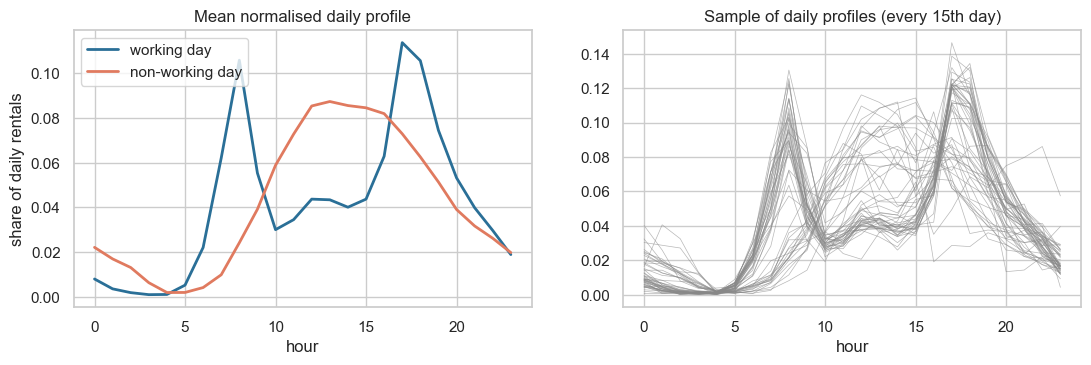

In [2]:
# day x 24 matrix of rentals (missing clock-hours -> 0)
M = hour.pivot_table(index='date', columns='hr', values='cnt', aggfunc='sum').reindex(columns=range(24)).fillna(0)
M_all = M; tot_all = M_all.sum(1); out_days = tot_all[tot_all < 500]
print('Near-empty days (< 500 rentals/day) excluded from the shape clustering because their profile is mostly sampling noise:', {str(k.date()): int(v) for k, v in out_days.items()})
R['excluded_days'] = {str(k.date()): int(v) for k, v in out_days.items()}
M = M_all[tot_all >= 500]
print('Day×hour matrix:', M.shape, '| days (before exclusion) with all 24 hours logged:', int((hour.groupby('date').size() == 24).sum()))
tot = M.sum(1); P = M.div(tot, axis=0).values            # shape profile: rows sum to 1
dinfo = day.set_index('date').loc[M.index]
print('Profile rows sum to 1:', np.allclose(P.sum(1), 1), '| min daily total', int(tot.min()), '(a near-empty day can have a noisy profile)')
sc_P = StandardScaler().fit(P); Z = sc_P.transform(P)  # per-hour standardisation, equal weight to each hour of the day
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for wd, c, l in [(1, '#2a6f97', 'working day'), (0, '#e07a5f', 'non-working day')]:
    ax[0].plot(range(24), P[(dinfo.workingday == wd).values].mean(0), color=c, lw=2, label=l)
ax[0].set(title='Mean normalised daily profile', xlabel='hour', ylabel='share of daily rentals'); ax[0].legend()
ax[1].plot(range(24), P[::15].T, color='#888', lw=.5, alpha=.6); ax[1].set(title='Sample of daily profiles (every 15th day)', xlabel='hour')
savefig('u3_fig01_profiles')

## 3. K-means *(Unit 3: K-means)*
Minimises the distortion $J=\sum_n\sum_k r_{nk}\lVert x_n-\mu_k\rVert^2$ by alternating assignment (E-like) and mean update (M-like) steps. $J$ never increases, but only a *local* minimum is found, so we use many restarts (`n_init=20`).
**Choosing $K$:** the elbow of $J$ is rarely sharp, so we also use the silhouette (higher is better) and the Davies–Bouldin index (lower is better); the three are looked at together.

,K,inertia J,silhouette,Davies-Bouldin,Calinski-Harabasz,ARI vs workingday
0,2,"8,725.9279",0.5044,0.8404,727.6760,0.9394
1,3,"7,914.2374",0.2393,1.5813,437.7793,0.5189
2,4,"7,125.0422",0.2463,1.3373,350.4633,0.5139
3,5,"6,619.7807",0.1662,1.6864,296.3147,0.4355
4,6,"6,251.6492",0.1444,1.7512,259.1666,0.3283
5,7,"5,934.8951",0.1547,1.6617,233.5973,0.3180
6,8,"5,695.3277",0.1369,1.7160,212.6857,0.2784


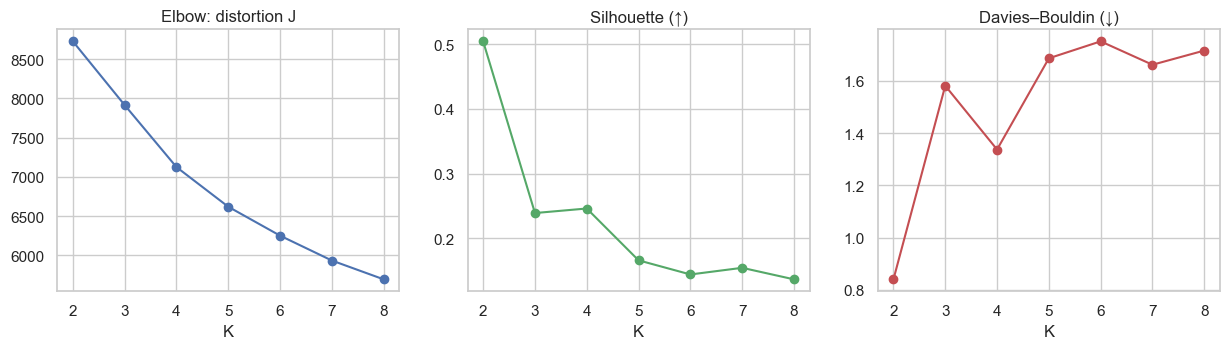

K with best silhouette = 2 | K with best Davies–Bouldin = 2


In [3]:
rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=20, random_state=SEED).fit(Z)
    rows.append({'K': k, 'inertia J': km.inertia_, 'silhouette': silhouette_score(Z, km.labels_),
                 'Davies-Bouldin': davies_bouldin_score(Z, km.labels_), 'Calinski-Harabasz': calinski_harabasz_score(Z, km.labels_),
                 'ARI vs workingday': adjusted_rand_score(dinfo.workingday, km.labels_)})
kdf = pd.DataFrame(rows); display(kdf)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].plot(kdf.K, kdf['inertia J'], 'o-'); ax[0].set(title='Elbow: distortion J', xlabel='K')
ax[1].plot(kdf.K, kdf.silhouette, 'o-', c='g'); ax[1].set(title='Silhouette (↑)', xlabel='K')
ax[2].plot(kdf.K, kdf['Davies-Bouldin'], 'o-', c='r'); ax[2].set(title='Davies–Bouldin (↓)', xlabel='K')
savefig('u3_fig02_kmeans_selection')
K_BEST = int(kdf.sort_values('silhouette', ascending=False).K.iloc[0]); R['kmeans_table'] = kdf.round(4).to_dict('records')
print('K with best silhouette =', K_BEST, '| K with best Davies–Bouldin =', int(kdf.sort_values('Davies-Bouldin').K.iloc[0]))

Assignment = nearest centre: True | centres = cluster means: True


workingday,0,1,n days,mean daily rentals,mean temp °C
cluster,,,,,
0,228,8,236,"4,252.8136",19.4421
1,3,489,492,"4,650.6524",20.7781


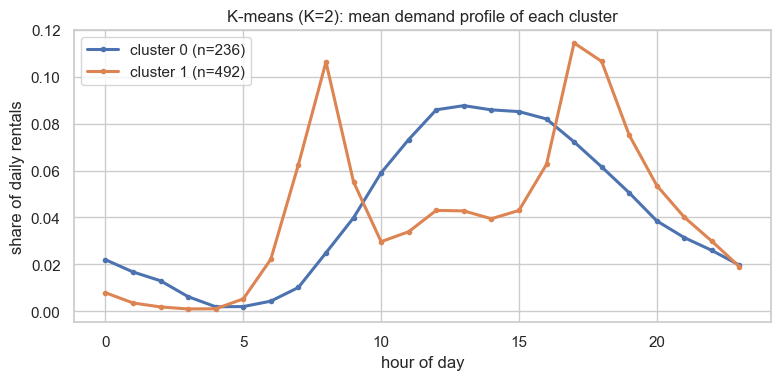

Days whose K-means cluster disagrees with their working-day flag: 11 | of these, official holidays: 3 | dates (first 12): ['2011-01-26', '2011-04-15', '2011-11-25', '2011-12-23', '2011-12-30', '2012-04-16', '2012-11-12', '2012-11-23', '2012-12-24', '2012-12-28', '2012-12-31']


{'K': 2, 'sil': 0.5043961900543726, 'DB': 0.8403734183941931, 'ARI_workingday': 0.9394101176988118, 'sizes': [236, 492], 'peak_hours': [13, 17]}


In [4]:
K = K_BEST   # chosen by silhouette AND Davies–Bouldin (both pick the same K); K=3 is examined as a finer view in §6
km = KMeans(K, n_init=20, random_state=SEED).fit(Z); lab_km = km.labels_
# verify K-means: J is a local minimum -> every point is assigned to its nearest centre, centres = cluster means
d2 = ((Z[:, None, :] - km.cluster_centers_[None]) ** 2).sum(2)
print('Assignment = nearest centre:', bool((d2.argmin(1) == lab_km).all()), '| centres = cluster means:', bool(np.allclose(km.cluster_centers_, np.vstack([Z[lab_km == k].mean(0) for k in range(K)]))))
ct = pd.crosstab(lab_km, [dinfo.workingday.values], rownames=['cluster'], colnames=['workingday']); ct['n days'] = ct.sum(1)
ct['mean daily rentals'] = [tot.values[lab_km == k].mean() for k in range(K)]; ct['mean temp °C'] = [dinfo.temp.values[lab_km == k].mean() * 41 for k in range(K)]
display(ct)
prof_km = np.vstack([P[lab_km == k].mean(0) for k in range(K)])
fig, ax = plt.subplots(figsize=(9, 3.8))
for k in range(K): ax.plot(range(24), prof_km[k], lw=2.2, marker='o', ms=3, label=f'cluster {k} (n={int((lab_km==k).sum())})')
ax.set(title=f'K-means (K={K}): mean demand profile of each cluster', xlabel='hour of day', ylabel='share of daily rentals'); ax.legend()
savefig('u3_fig03_kmeans_profiles')
wd_major = {c: int(pd.Series(dinfo.workingday.values[lab_km == c]).mode()[0]) for c in range(K)}; mism = dinfo[[wd_major[c] != w for c, w in zip(lab_km, dinfo.workingday.values)]]
print('Days whose K-means cluster disagrees with their working-day flag:', len(mism), '| of these, official holidays:', int(mism.holiday.sum()), '| dates (first 12):', [str(d.date()) for d in mism.index[:12]])
R['kmeans_mismatch'] = {'n': int(len(mism)), 'holidays': int(mism.holiday.sum())}
R['kmeans'] = {'K': K, 'sil': float(silhouette_score(Z, lab_km)), 'DB': float(davies_bouldin_score(Z, lab_km)), 'ARI_workingday': float(adjusted_rand_score(dinfo.workingday, lab_km)), 'sizes': [int((lab_km == k).sum()) for k in range(K)],
              'peak_hours': [int(prof_km[k].argmax()) for k in range(K)]}
print(R['kmeans'])

## 4. Mixture of Gaussians and EM *(Unit 3: mixtures of Gaussians, EM – alternative view)*
GMM: $p(x)=\sum_k\pi_k\mathcal N(x\mid\mu_k,\Sigma_k)$. **EM** alternates responsibilities $\gamma_{nk}=\pi_k\mathcal N(x_n|\mu_k,\Sigma_k)/\sum_j\pi_j\mathcal N(x_n|\mu_j,\Sigma_j)$ (E-step) and re-estimation of $\pi,\mu,\Sigma$ (M-step). In the *alternative view* EM maximises the lower bound $\mathcal L(q,\theta)=\mathbb E_q[\ln p(X,Z|\theta)]+H(q)$, so the log-likelihood **cannot decrease** – verified below. K-means is the limit $\Sigma_k=\epsilon I,\ \epsilon\to0$ (hard assignments).

Because the profiles live in 24 dimensions with only 731 days, full covariances would overfit; the GMM is therefore fitted in the **leading principal components** that retain 90% of the profile variance (PCA, see §7) with full covariance, and $K$ is chosen by **BIC**.

In [5]:
pca_d = PCA(n_components=0.90, random_state=SEED).fit(Z); Zp = pca_d.transform(Z)
print('PCs kept for 90%% of profile variance: %d (variance kept %.3f)' % (pca_d.n_components_, pca_d.explained_variance_ratio_.sum()))
def logsumexp(a, axis=1):
    m = a.max(axis, keepdims=True); return (m + np.log(np.exp(a - m).sum(axis, keepdims=True))).squeeze(axis)
def log_gauss(X, mu, S):
    d = X.shape[1]; L = np.linalg.cholesky(S); sol = np.linalg.solve(L, (X - mu).T)
    return -.5 * (d * np.log(2 * np.pi) + 2 * np.log(np.diag(L)).sum() + (sol ** 2).sum(0))
def gmm_em(X, K, iters=300, tol=1e-8, seed=0, reg=1e-6):
    rng = np.random.RandomState(seed); N, d = X.shape
    km_ = KMeans(K, n_init=1, random_state=seed).fit(X)
    mu = km_.cluster_centers_.copy(); pi = np.bincount(km_.labels_, minlength=K) / N
    S = np.stack([np.cov(X[km_.labels_ == k].T) + reg * np.eye(d) for k in range(K)]); ll_hist = []
    for it in range(iters):
        lp = np.stack([np.log(pi[k]) + log_gauss(X, mu[k], S[k]) for k in range(K)], 1)          # E-step
        ll = logsumexp(lp).sum(); ll_hist.append(ll); g = np.exp(lp - logsumexp(lp)[:, None])
        Nk = g.sum(0); pi = Nk / N; mu = (g.T @ X) / Nk[:, None]                                   # M-step
        S = np.stack([((g[:, k, None] * (X - mu[k])).T @ (X - mu[k])) / Nk[k] + reg * np.eye(d) for k in range(K)])
        if it > 0 and abs(ll_hist[-1] - ll_hist[-2]) < tol * abs(ll_hist[-2]): break
    return dict(pi=pi, mu=mu, S=S, ll=ll_hist[-1], hist=np.array(ll_hist), resp=g)
rows = []; best = {}
for k in range(1, 8):
    fits = [gmm_em(Zp, k, seed=s) for s in range(5)]; f = max(fits, key=lambda r: r['ll']); best[k] = f
    npar = k * Zp.shape[1] + k * Zp.shape[1] * (Zp.shape[1] + 1) / 2 + (k - 1)
    rows.append({'K': k, 'logL (own EM)': f['ll'], 'params': int(npar), 'BIC': -2 * f['ll'] + npar * np.log(len(Zp)), 'EM iterations': len(f['hist'])})
gdf = pd.DataFrame(rows); display(gdf)
maxdrop = max(-np.diff(best[k]['hist']).min() for k in best if len(best[k]['hist']) > 1); mono = maxdrop < 1e-3
print('EM log-likelihood non-decreasing (largest single-step drop over all K and iterations = %.2e log-lik units; tiny drops come from the 1e-6·I covariance regulariser added in the M-step): %s' % (maxdrop, mono))
sk = GaussianMixture(K, covariance_type='full', n_init=5, random_state=SEED, reg_covar=1e-6).fit(Zp)
print('Cross-check K=%d: own EM logL = %.3f | sklearn GaussianMixture logL = %.3f' % (K, best[K]['ll'], sk.score(Zp) * len(Zp)))
K_GMM = int(gdf.sort_values('BIC').K.iloc[0]); print('K chosen by BIC:', K_GMM)
R['gmm'] = {'BIC_table': gdf.round(3).to_dict('records'), 'K_BIC': K_GMM, 'em_monotone': bool(mono), 'em_max_drop': float(maxdrop), 'sk_ll_K': float(sk.score(Zp) * len(Zp)), 'own_ll_K': float(best[K]['ll']), 'n_pc': int(pca_d.n_components_)}

PCs kept for 90% of profile variance: 7 (variance kept 0.907)


,K,logL (own EM),params,BIC,EM iterations
0,1,"-8,418.6343",35,"17,067.9291",3
1,2,"-7,265.3479",71,"14,998.6071",7
2,3,"-6,715.7218",107,"14,136.6059",35
3,4,"-6,509.6009",143,"13,961.6149",41
4,5,"-6,432.5491",179,"14,044.7621",27
5,6,"-6,316.4343",215,"14,049.7833",71
6,7,"-6,181.7366",251,"14,017.6387",58


EM log-likelihood non-decreasing (largest single-step drop over all K and iterations = -0.00e+00 log-lik units; tiny drops come from the 1e-6·I covariance regulariser added in the M-step): True
Cross-check K=2: own EM logL = -7265.348 | sklearn GaussianMixture logL = -7265.349
K chosen by BIC: 4


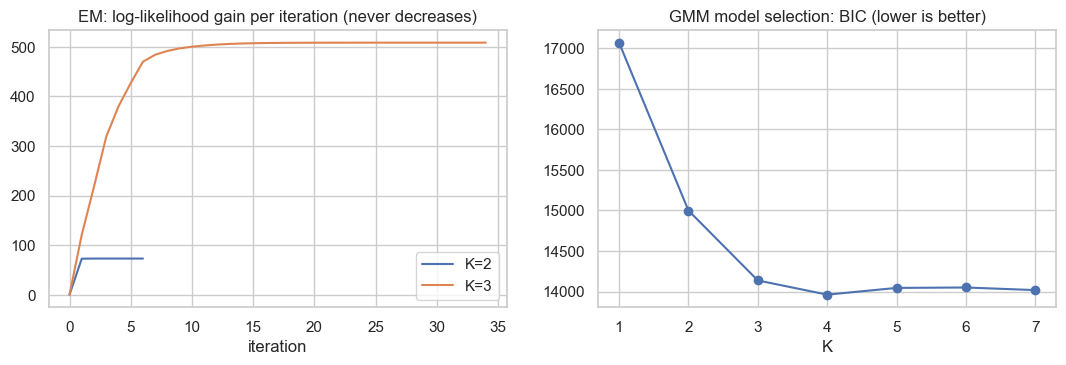

GMM K=2 (same K as K-means for a like-for-like comparison; BIC alone would choose K=4): sizes [239, 489] | ARI vs workingday = 0.923 | ARI vs K-means = 0.972
Soft assignment: days with max responsibility < 0.9 = 1 (K-means would force a hard label on these)
Mixing weights π: [0.329 0.671]


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for k in sorted({2, K, K + 1}): ax[0].plot(best[k]['hist'] - best[k]['hist'][0], label=f'K={k}')
ax[0].set(title='EM: log-likelihood gain per iteration (never decreases)', xlabel='iteration'); ax[0].legend()
ax[1].plot(gdf.K, gdf.BIC, 'o-'); ax[1].set(title='GMM model selection: BIC (lower is better)', xlabel='K')
savefig('u3_fig04_gmm')
Kg = K; g3 = best[Kg]; lab_gmm = g3['resp'].argmax(1); unc = 1 - g3['resp'].max(1)
print(f'GMM K={Kg} (same K as K-means for a like-for-like comparison; BIC alone would choose K={K_GMM}): sizes', np.bincount(lab_gmm).tolist(), '| ARI vs workingday = %.3f | ARI vs K-means = %.3f' % (adjusted_rand_score(dinfo.workingday, lab_gmm), adjusted_rand_score(lab_km, lab_gmm)))
print('Soft assignment: days with max responsibility < 0.9 =', int((g3['resp'].max(1) < .9).sum()), '(K-means would force a hard label on these)')
print('Mixing weights π:', g3['pi'].round(3))
R['gmm'].update({'ARI_workingday': float(adjusted_rand_score(dinfo.workingday, lab_gmm)), 'ARI_vs_kmeans': float(adjusted_rand_score(lab_km, lab_gmm)), 'uncertain_days': int((g3['resp'].max(1) < .9).sum())})

## 5. Hierarchical clustering and dissimilarity measures *(Unit 3: dissimilarity measures, hierarchical clustering)*
Agglomerative clustering repeatedly merges the two closest clusters; the result is a **dendrogram** and needs no pre-set $K$. The *dissimilarity* between points (Euclidean, cosine, correlation) and between clusters (single, complete, average, Ward linkage) both matter. The **cophenetic correlation** measures how faithfully the dendrogram preserves the original pairwise distances.

,dissimilarity,linkage,cophenetic corr,silhouette (cut at K),ARI vs workingday,cluster sizes
0,euclidean,single,0.7780,0.7277,0.0032,"[727, 1]"
1,euclidean,complete,0.7934,0.6910,0.0095,"[3, 725]"
2,euclidean,average,0.9163,0.6910,0.0095,"[725, 3]"
3,euclidean,ward,0.7316,0.4996,0.9502,"[500, 228]"
4,cosine,single,0.4972,0.0286,-0.0015,"[727, 1]"
5,cosine,complete,0.7264,0.6783,0.9020,"[245, 483]"
6,cosine,average,0.9096,0.6628,0.8502,"[257, 471]"
7,correlation,single,0.5286,0.0267,-0.0015,"[727, 1]"
8,correlation,complete,0.6830,0.6613,0.9019,"[241, 487]"
9,correlation,average,0.9255,0.6815,0.9126,"[243, 485]"


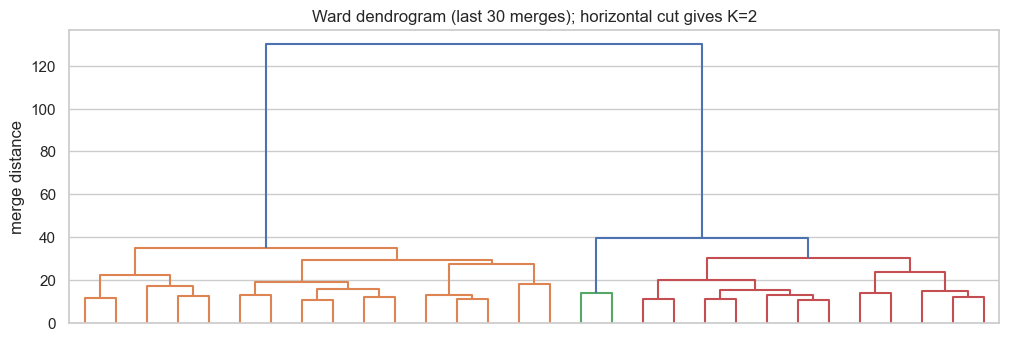

Ward K=2 sizes: [500, 228] | ARI vs K-means 0.945 | ARI vs GMM 0.929 | ARI vs workingday 0.950


In [7]:
rows = []
for metric in ['euclidean', 'cosine', 'correlation']:
    D = pdist(Z, metric)
    for meth in ['single', 'complete', 'average'] + (['ward'] if metric == 'euclidean' else []):
        Lk = linkage(D, meth) if meth != 'ward' else linkage(Z, 'ward')
        lab = fcluster(Lk, K, 'maxclust'); c, _ = cophenet(Lk, D)
        rows.append({'dissimilarity': metric, 'linkage': meth, 'cophenetic corr': c, 'silhouette (cut at K)': silhouette_score(Z, lab, metric=metric) if len(set(lab)) > 1 else np.nan,
                     'ARI vs workingday': adjusted_rand_score(dinfo.workingday, lab), 'cluster sizes': np.bincount(lab)[1:].tolist()})
hdf = pd.DataFrame(rows); display(hdf); R['hier_table'] = hdf.assign(**{'cluster sizes': hdf['cluster sizes'].astype(str)}).round(4).to_dict('records')
Lw = linkage(Z, 'ward'); lab_h = fcluster(Lw, K, 'maxclust') - 1
fig, ax = plt.subplots(figsize=(12, 3.8)); dendrogram(Lw, truncate_mode='lastp', p=30, ax=ax, color_threshold=Lw[-K, 2], no_labels=True)
ax.set(title='Ward dendrogram (last 30 merges); horizontal cut gives K=%d' % K, ylabel='merge distance'); savefig('u3_fig05_dendrogram')
print('Ward K=%d sizes:' % K, np.bincount(lab_h).tolist(), '| ARI vs K-means %.3f | ARI vs GMM %.3f | ARI vs workingday %.3f' % (adjusted_rand_score(lab_km, lab_h), adjusted_rand_score(lab_gmm, lab_h), adjusted_rand_score(dinfo.workingday, lab_h)))
R['hier'] = {'ARI_vs_kmeans': float(adjusted_rand_score(lab_km, lab_h)), 'ARI_vs_gmm': float(adjusted_rand_score(lab_gmm, lab_h)), 'ARI_workingday': float(adjusted_rand_score(dinfo.workingday, lab_h)), 'ward_coph': float(hdf[(hdf.linkage == 'ward')]['cophenetic corr'].iloc[0])}

## 6. Cluster evaluation – all three methods side by side *(silhouette, Davies–Bouldin, external ARI)*
Internal indices use only the data; ARI compares with the known working-day label (which clustering never saw). Perfect agreement with `workingday` is **not** expected – holidays, weather-hit days and weekend days with commuter-like profiles genuinely differ.

,Method,K,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI vs workingday,ARI vs season,ARI vs weekday
0,K-means,2,0.5044,0.8404,727.6760,0.9394,0.0004,0.1948
1,"GMM (EM, full cov, PCA space)",2,0.5018,0.8538,713.9230,0.9233,0.0003,0.1932
2,Hierarchical (Ward),2,0.4996,0.8505,686.3291,0.9502,-0.0009,0.1983
3,"K-means, finer view K=3",3,0.2393,1.5813,437.7793,0.5189,0.0490,0.2369


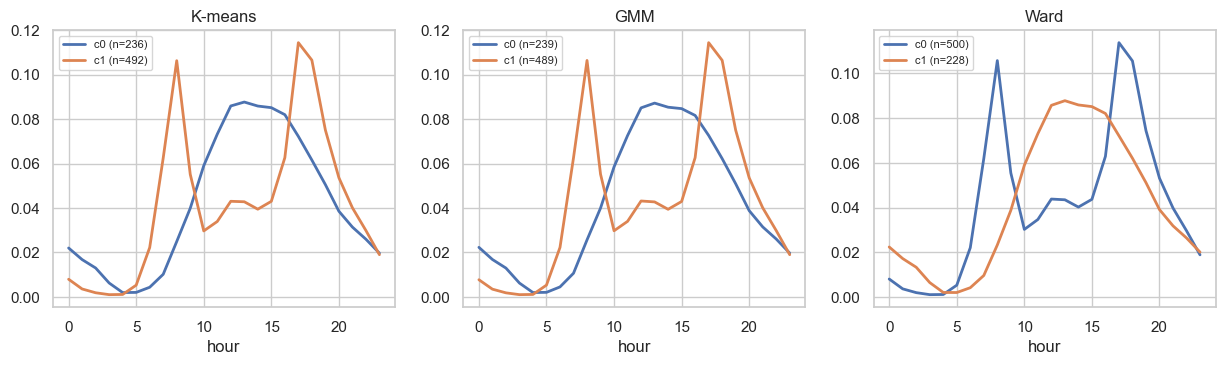

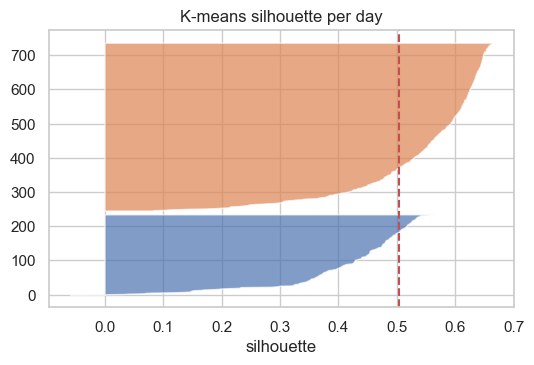

Days with negative silhouette (possibly mis-clustered): 2 of 728


In [8]:
def cmp(name, lab, X=Z):
    return {'Method': name, 'K': len(set(lab)), 'Silhouette': silhouette_score(X, lab), 'Davies-Bouldin': davies_bouldin_score(X, lab), 'Calinski-Harabasz': calinski_harabasz_score(X, lab),
            'ARI vs workingday': adjusted_rand_score(dinfo.workingday, lab), 'ARI vs season': adjusted_rand_score(dinfo.season, lab), 'ARI vs weekday': adjusted_rand_score(dinfo.weekday, lab)}
km3 = KMeans(3, n_init=20, random_state=SEED).fit(Z).labels_
ev = pd.DataFrame([cmp('K-means', lab_km), cmp('GMM (EM, full cov, PCA space)', lab_gmm), cmp('Hierarchical (Ward)', lab_h), cmp('K-means, finer view K=3', km3)]); display(ev)
R['cluster_eval'] = ev.round(4).to_dict('records')
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, lab, t in zip(ax, [lab_km, lab_gmm, lab_h], ['K-means', 'GMM', 'Ward']):
    pr = np.vstack([P[lab == k].mean(0) for k in range(K)])
    for k in range(K): a.plot(range(24), pr[k], lw=2, label=f'c{k} (n={(lab==k).sum()})')
    a.set(title=t, xlabel='hour'); a.legend(fontsize=8)
savefig('u3_fig06_methods_profiles')
# silhouette plot for K-means
from sklearn.metrics import silhouette_samples
sv = silhouette_samples(Z, lab_km); fig, ax = plt.subplots(figsize=(6, 3.6)); y0 = 0
for k in range(K):
    s = np.sort(sv[lab_km == k]); ax.fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, alpha=.7); y0 += len(s) + 10
ax.axvline(sv.mean(), c='r', ls='--'); ax.set(title='K-means silhouette per day', xlabel='silhouette'); savefig('u3_fig07_silhouette')
print('Days with negative silhouette (possibly mis-clustered): %d of %d' % ((sv < 0).sum(), len(sv)))

## 7. PCA of weather–time features *(Unit 3: PCA, choosing latent dimensions – Practice 2)*
PCA finds the orthogonal directions of maximum variance: the eigenvectors of the covariance matrix $S$ of the standardised data; the eigenvalues are the variances along them. Retaining $M$ components gives reconstruction error $\sum_{i>M}\lambda_i$. **Choosing $M$:** scree plot, cumulative explained variance, Kaiser rule ($\lambda>1$ on standardised data) and cross-validated reconstruction error.

Features (hourly): `temp, atemp, hum, windspeed` plus cyclic encodings of hour ($\sin,\cos$ of $2\pi\,hr/24$) and month, `workingday, holiday, weathersit`.

Own eigenvalues = sklearn explained_variance_: True | components equal up to sign: True


,PC,eigenvalue,explained var,cumulative
0,1,2.9358,0.2669,0.2669
1,2,1.7999,0.1636,0.4305
2,3,1.2620,0.1147,0.5452
3,4,1.1119,0.1011,0.6463
4,5,0.9806,0.0891,0.7354
5,6,0.9281,0.0844,0.8198
6,7,0.7533,0.0685,0.8883
7,8,0.7170,0.0652,0.9534
8,9,0.3539,0.0322,0.9856
9,10,0.1519,0.0138,0.9994


Test reconstruction MSE falls monotonically with M: True
Check: mean squared reconstruction error of the training data with M=4 equals the sum of the dropped eigenvalues -> True (eigenvalues use the N-1 covariance)


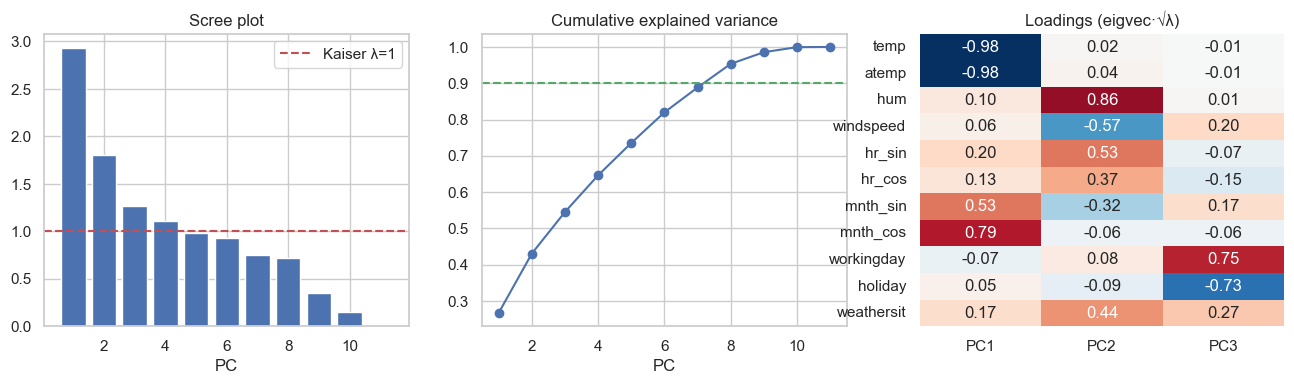

Components for 90% variance: 8 | Kaiser (λ>1): 4


,PC1,PC2,PC3
temp,-0.9850,0.0160,-0.0060
atemp,-0.9800,0.0390,-0.0070
hum,0.1030,0.8630,0.0130
windspeed,0.0560,-0.5730,0.1970
hr_sin,0.1980,0.5250,-0.0700
hr_cos,0.1250,0.3680,-0.1460
mnth_sin,0.5300,-0.3220,0.1750
mnth_cos,0.7870,-0.0610,-0.0550
workingday,-0.0660,0.0840,0.7480
holiday,0.0540,-0.0900,-0.7310


In [9]:
def wt_features(df):
    return pd.DataFrame({'temp': df.temp, 'atemp': df.atemp, 'hum': df.hum, 'windspeed': df.windspeed,
        'hr_sin': np.sin(2 * np.pi * df.hr / 24), 'hr_cos': np.cos(2 * np.pi * df.hr / 24),
        'mnth_sin': np.sin(2 * np.pi * df.mnth / 12), 'mnth_cos': np.cos(2 * np.pi * df.mnth / 12),
        'workingday': df.workingday, 'holiday': df.holiday, 'weathersit': df.weathersit}).astype(float)
Wtr, Wte = wt_features(train), wt_features(test)
sc_w = StandardScaler().fit(Wtr); Wtr_s, Wte_s = sc_w.transform(Wtr), sc_w.transform(Wte)        # fitted on TRAIN only
# --- PCA from scratch via eigen-decomposition
Sx = np.cov(Wtr_s.T); lam, V = np.linalg.eigh(Sx); o = np.argsort(lam)[::-1]; lam, V = lam[o], V[:, o]
ref = PCA().fit(Wtr_s)
print('Own eigenvalues = sklearn explained_variance_:', np.allclose(lam, ref.explained_variance_), '| components equal up to sign:', np.allclose(np.abs(V.T), np.abs(ref.components_), atol=1e-6))
evr = lam / lam.sum(); cum = evr.cumsum()
tabp = pd.DataFrame({'PC': range(1, len(lam) + 1), 'eigenvalue': lam, 'explained var': evr, 'cumulative': cum}); display(tabp)
def recon_mse(M_): Vm = V[:, :M_]; return ((Wte_s - Wte_s @ Vm @ Vm.T) ** 2).mean()
tabp['held-out recon MSE (test)'] = [recon_mse(m) for m in range(1, len(lam) + 1)]
print('Test reconstruction MSE falls monotonically with M:', bool(np.all(np.diff(tabp['held-out recon MSE (test)']) < 1e-9)))
print('Check: mean squared reconstruction error of the training data with M=4 equals the sum of the dropped eigenvalues ->', np.isclose(((Wtr_s - Wtr_s @ V[:, :4] @ V[:, :4].T) ** 2).sum(1).mean(), lam[4:].sum() * (len(Wtr_s) - 1) / len(Wtr_s)), '(eigenvalues use the N-1 covariance)')
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].bar(tabp.PC, lam); ax[0].axhline(1, c='r', ls='--', label='Kaiser λ=1'); ax[0].set(title='Scree plot', xlabel='PC'); ax[0].legend()
ax[1].plot(tabp.PC, cum, 'o-'); ax[1].axhline(.9, c='g', ls='--'); ax[1].set(title='Cumulative explained variance', xlabel='PC')
Ld = pd.DataFrame(V[:, :3] * np.sqrt(lam[:3]), index=Wtr.columns, columns=['PC1', 'PC2', 'PC3']); sns.heatmap(Ld, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[2], cbar=False); ax[2].set_title('Loadings (eigvec·√λ)')
savefig('u3_fig08_pca')
M90 = int(np.searchsorted(cum, .90) + 1); Mk = int((lam > 1).sum()); print(f'Components for 90% variance: {M90} | Kaiser (λ>1): {Mk}')
R['pca'] = {'eigenvalues': lam.round(4).tolist(), 'cum': cum.round(4).tolist(), 'M90': M90, 'Kaiser': Mk, 'matches_sklearn': bool(np.allclose(lam, ref.explained_variance_))}
display(Ld.round(3))

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
corr with log1p(cnt) (train),-0.4200,-0.4425,0.0762,0.1889,-0.0100,0.2151,-0.1087,0.2667


Test R² for log1p(cnt) with a linear model:  all 11 features 0.485 | 8 PCs 0.484 | first 2 PCs 0.207


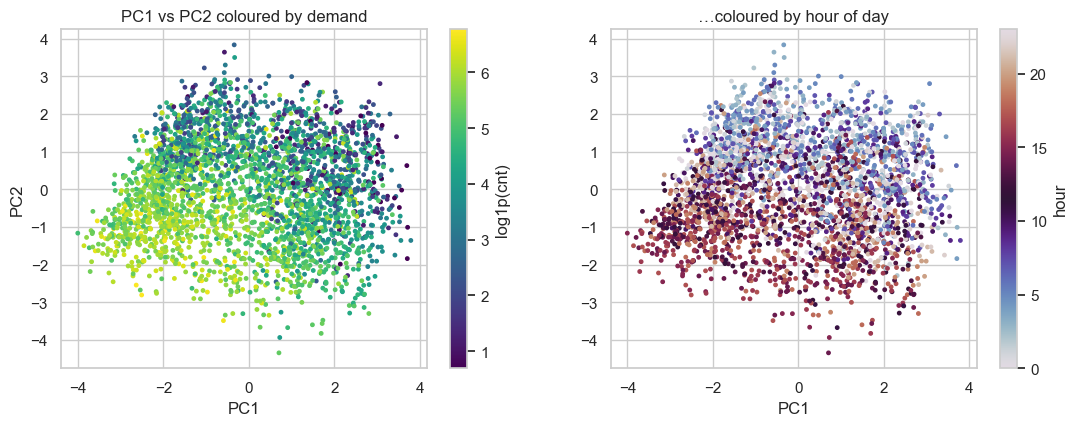

In [10]:
# Does the latent space carry demand information? (the PCs never saw cnt)
Ttr = Wtr_s @ V[:, :M90]; Tte = Wte_s @ V[:, :M90]
cr = pd.DataFrame({f'PC{i+1}': [np.corrcoef(Ttr[:, i], np.log1p(train.cnt))[0, 1]] for i in range(M90)}, index=['corr with log1p(cnt) (train)']); display(cr)
def ridge_r2(Xa, Xb): m = Ridge(1.0).fit(Xa, np.log1p(train.cnt)); return r2_score(np.log1p(test.cnt), m.predict(Xb))
r_all = ridge_r2(Wtr_s, Wte_s); r_pc = ridge_r2(Ttr, Tte); r_2 = ridge_r2(Ttr[:, :2], Tte[:, :2])
print('Test R² for log1p(cnt) with a linear model:  all 11 features %.3f | %d PCs %.3f | first 2 PCs %.3f' % (r_all, M90, r_pc, r_2))
R['pca'].update({'r2_all': float(r_all), 'r2_pc': float(r_pc), 'r2_2pc': float(r_2)})
# 2-D map coloured by demand and by hour
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4)); sub = np.random.RandomState(0).choice(len(Ttr), 3000, replace=False)
s0 = ax[0].scatter(Ttr[sub, 0], Ttr[sub, 1], c=np.log1p(train.cnt.values[sub]), cmap='viridis', s=6); plt.colorbar(s0, ax=ax[0], label='log1p(cnt)'); ax[0].set(title='PC1 vs PC2 coloured by demand', xlabel='PC1', ylabel='PC2')
s1 = ax[1].scatter(Ttr[sub, 0], Ttr[sub, 1], c=train.hr.values[sub], cmap='twilight', s=6); plt.colorbar(s1, ax=ax[1], label='hour'); ax[1].set(title='…coloured by hour of day', xlabel='PC1')
savefig('u3_fig09_pca_map')

## 8. Factor analysis *(Unit 3: factor analysis)*
FA models $x=Wz+\mu+\epsilon$, $z\sim\mathcal N(0,I)$, $\epsilon\sim\mathcal N(0,\Psi)$ with a **diagonal** noise $\Psi$: it separates shared (common-factor) variance from feature-specific noise, whereas PCA treats all variance alike (it is the $\Psi=\sigma^2I,\ \sigma\to0$ limit of probabilistic PCA). Latent dimension is chosen by held-out log-likelihood.

In [11]:
rows = []
for q in range(1, 9):
    fa = FactorAnalysis(q, random_state=SEED).fit(Wtr_s); rows.append({'latent dim q': q, 'train avg logL': fa.score(Wtr_s), 'test avg logL': fa.score(Wte_s)})
fdf = pd.DataFrame(rows); display(fdf)
q_best = int(fdf.sort_values('test avg logL', ascending=False)['latent dim q'].iloc[0]); fa = FactorAnalysis(q_best, random_state=SEED).fit(Wtr_s)
print('q with best held-out log-likelihood:', q_best)
com = pd.DataFrame({'communality (shared var)': (fa.components_ ** 2).sum(0), 'noise variance Ψ': fa.noise_variance_}, index=Wtr.columns); display(com)
print('Features with Ψ small (explained by common factors):', list(com[com['noise variance Ψ'] < .2].index))
R['fa'] = {'q_best': q_best, 'table': fdf.round(4).to_dict('records')}

,latent dim q,train avg logL,test avg logL
0,1,-12.9321,-14.8004
1,2,-12.6506,-14.5923
2,3,-12.4552,-14.1182
3,4,-12.3814,-14.1145
4,5,-12.3448,-14.0965
5,6,-12.3055,-14.0349
6,7,-12.2662,-14.0416
7,8,-12.2624,-14.0411


q with best held-out log-likelihood: 6


,communality (shared var),noise variance Ψ
temp,0.9998,0.0002
atemp,0.9876,0.0124
hum,0.9709,0.0291
windspeed,0.4665,0.5335
hr_sin,0.9483,0.0517
hr_cos,0.1795,0.8205
mnth_sin,0.5174,0.4826
mnth_cos,0.9902,0.0098
workingday,0.2717,0.7283
holiday,0.2106,0.7894


Features with Ψ small (explained by common factors): ['temp', 'atemp', 'hum', 'hr_sin', 'mnth_cos']


# UNIT 4 – Sequential models: HMM and Kalman filter
## 9. Data for sequence models
The hourly series $z_t=\ln(1+cnt_t)$ is used (log scale: roughly constant noise, §Unit 2). The 165 clock-hours absent in `hour.csv` are gaps in the sequence; they are ignored (the sequence stays in time order), which is a small approximation and is stated as a limitation.

In [12]:
z_all = np.log1p(hour.cnt.values.astype(float)); z_tr = z_all[:n_train]; z_te = z_all[n_train:]
print('Sequence length: train', len(z_tr), '| test', len(z_te), '| z range', z_all.min().round(2), '–', z_all.max().round(2))

Sequence length: train 13903 | test 3476 | z range 0.69 – 6.89


## 10. Hidden Markov Model – from scratch *(Markov models, HMM, forward–backward, scaling, Baum–Welch, Viterbi)*
Hidden state $s_t\in\{1..K\}$ follows a first-order Markov chain $p(s_t=j|s_{t-1}=i)=A_{ij}$, initial $\pi$; emission $p(z_t|s_t=k)=\mathcal N(\mu_k,\sigma_k^2)$.

* **Forward** $\alpha_t(k)=p(z_{1:t},s_t=k)$; scaled: $\hat\alpha_t=\alpha_t/c_t$ with $c_t=p(z_t|z_{1:t-1})$, so $\ln p(Z)=\sum_t\ln c_t$ and nothing underflows (*scaling factors*).
* **Backward** $\hat\beta_t=\beta_t/\prod_{u>t}c_u$ → state posteriors $\gamma_t(k)=\hat\alpha_t(k)\hat\beta_t(k)$ and pair posteriors $\xi_t(i,j)=\hat\alpha_{t}(i)A_{ij}b_{t+1}(j)\hat\beta_{t+1}(j)/c_{t+1}$ (the sum-product algorithm on the chain).
* **Baum–Welch (EM for HMM)**: M-step $A_{ij}=\sum_t\xi_t(i,j)/\sum_t\gamma_t(i)$, $\mu_k,\sigma_k^2$ = $\gamma$-weighted mean/variance.
* **Viterbi**: $\delta_t(k)=\max_i\delta_{t-1}(i)A_{ik}\,b_t(k)$ in log space with back-pointers → the single most probable state sequence.

In [13]:
class GaussHMM:
    def __init__(self, K, seed=0): self.K, self.seed = K, seed
    def init(self, z):
        K = self.K; q = np.quantile(z, np.linspace(0, 1, K + 1)); 
        self.mu = np.array([z[(z >= q[k]) & (z <= q[k + 1])].mean() for k in range(K)]); self.var = np.full(K, z.var() / K)
        rng = np.random.RandomState(self.seed); self.A = .8 * np.eye(K) + .2 / K + .02 * rng.rand(K, K); self.A /= self.A.sum(1, keepdims=True); self.pi = np.full(K, 1 / K)
        self.mu = self.mu + .05 * rng.randn(K)
    def emis(self, z):  # b[t,k] = N(z_t | mu_k, var_k)
        return np.maximum(np.exp(-.5 * (z[:, None] - self.mu) ** 2 / self.var) / np.sqrt(2 * np.pi * self.var), 1e-300)
    def forward(self, z, B=None):
        B = self.emis(z) if B is None else B; T = len(z); al = np.zeros((T, self.K)); c = np.zeros(T)
        a = self.pi * B[0]; c[0] = a.sum(); al[0] = a / c[0]
        for t in range(1, T): a = (al[t - 1] @ self.A) * B[t]; c[t] = a.sum(); al[t] = a / c[t]
        return al, c
    def backward(self, z, c, B=None):
        B = self.emis(z) if B is None else B; T = len(z); be = np.ones((T, self.K))
        for t in range(T - 2, -1, -1): be[t] = self.A @ (B[t + 1] * be[t + 1]) / c[t + 1]
        return be
    def loglik(self, z): return np.log(self.forward(z)[1]).sum()
    def fit(self, z, iters=200, tol=1e-7):
        self.init(z); T = len(z); self.hist = []
        for it in range(iters):
            B = self.emis(z); al, c = self.forward(z, B); be = self.backward(z, c, B); self.hist.append(np.log(c).sum())
            g = al * be; xi_sum = np.zeros((self.K, self.K))
            xi_sum = self.A * (al[:-1].T @ (B[1:] * be[1:] / c[1:, None]))
            self.pi = g[0]; self.A = xi_sum / xi_sum.sum(1, keepdims=True); Nk = g.sum(0)
            self.mu = (g * z[:, None]).sum(0) / Nk; self.var = np.maximum((g * (z[:, None] - self.mu) ** 2).sum(0) / Nk, 1e-4)
            if it > 0 and abs(self.hist[-1] - self.hist[-2]) < tol * abs(self.hist[-2]): break
        return self
    def posterior(self, z): al, c = self.forward(z); be = self.backward(z, c); return al * be
    def viterbi(self, z):
        B = self.emis(z); T = len(z); lA = np.log(self.A + 1e-300); d = np.log(self.pi + 1e-300) + np.log(B[0]); bp = np.zeros((T, self.K), int)
        for t in range(1, T): s = d[:, None] + lA; bp[t] = s.argmax(0); d = s.max(0) + np.log(B[t])
        path = np.zeros(T, int); path[-1] = d.argmax()
        for t in range(T - 2, -1, -1): path[t] = bp[t + 1, path[t + 1]]
        return path, d.max()
# ---- correctness checks against brute force on a tiny sequence (K=2,T=6): enumerate all 2^6 state paths
tiny = GaussHMM(2); tz = z_tr[:6]; tiny.init(tz); Bt = tiny.emis(tz); best_p, best_path, tot_p = -1, None, 0
for path in itertools.product(range(2), repeat=6):
    p = tiny.pi[path[0]] * Bt[0, path[0]]
    for t in range(1, 6): p *= tiny.A[path[t - 1], path[t]] * Bt[t, path[t]]
    tot_p += p
    if p > best_p: best_p, best_path = p, path
print('Brute force  : log p(Z) = %.10f | best path %s' % (np.log(tot_p), best_path))
print('Forward alg. : log p(Z) = %.10f | Viterbi path %s' % (tiny.loglik(tz), tuple(tiny.viterbi(tz)[0])))
chk_fb = np.isclose(np.log(tot_p), tiny.loglik(tz)); chk_vit = tuple(tiny.viterbi(tz)[0]) == best_path and np.isclose(tiny.viterbi(tz)[1], np.log(best_p))
g_ = tiny.posterior(tz); print('Posterior rows sum to 1:', np.allclose(g_.sum(1), 1), '| forward-backward == brute-force check:', bool(chk_fb), '| Viterbi == brute-force argmax:', bool(chk_vit))
R['hmm_checks'] = {'forward_matches_bruteforce': bool(chk_fb), 'viterbi_matches_bruteforce': bool(chk_vit)}

Brute force  : log p(Z) = -8.8409881580 | best path (1, 1, 1, 1, 0, 0)
Forward alg. : log p(Z) = -8.8409881580 | Viterbi path (1, 1, 1, 1, 0, 0)
Posterior rows sum to 1: True | forward-backward == brute-force check: True | Viterbi == brute-force argmax: True


In [14]:
# ---- model selection: K by BIC on TRAINING data, several restarts
rows, models = [], {}
for K_ in range(2, 7):
    fits = [GaussHMM(K_, seed=s).fit(z_tr) for s in range(4)]; m = max(fits, key=lambda h: h.hist[-1]); models[K_] = m
    npar = K_ * K_ - 1 + 2 * K_ + (K_ - 1) - (K_ - 1) + (K_ - 1) * 0   # A: K(K-1), pi: K-1, mu: K, var: K
    npar = K_ * (K_ - 1) + (K_ - 1) + 2 * K_
    rows.append({'K': K_, 'train logL': m.hist[-1], 'test logL (avg per hour)': m.loglik(np.r_[z_tr[-200:], z_te]) / (len(z_te) + 200) , 'params': npar, 'BIC (train)': -2 * m.hist[-1] + npar * np.log(len(z_tr)), 'EM iters': len(m.hist)})
hmm_df = pd.DataFrame(rows); display(hmm_df)
print('Baum–Welch log-likelihood non-decreasing (all K):', all(np.all(np.diff(models[k].hist) > -1e-6) for k in models))
R['hmm_table'] = hmm_df.round(3).to_dict('records'); R['hmm_em_monotone'] = bool(all(np.all(np.diff(models[k].hist) > -1e-6) for k in models))
print('K by BIC:', int(hmm_df.sort_values('BIC (train)').K.iloc[0]), '(BIC keeps preferring more states because the data are a long series with strong daily structure; we use K=4 as a compromise for interpretability, see text)')

,K,train logL,test logL (avg per hour),params,BIC (train),EM iters
0,2,"-18,367.8584",-1.3301,7,"36,802.4957",14
1,3,"-16,013.3546",-1.1727,14,"32,160.2672",60
2,4,"-14,503.9608",-1.0638,23,"29,227.3384",86
3,5,"-13,348.9077",-1.0174,34,"27,022.1706",110
4,6,"-12,452.2864",-0.9394,47,"25,352.9463",86


Baum–Welch log-likelihood non-decreasing (all K): True
K by BIC: 6 (BIC keeps preferring more states because the data are a long series with strong daily structure; we use K=4 as a compromise for interpretability, see text)


,state,mean log1p(cnt),std,typical cnt (expm1 mean),share of training hours (Viterbi),mean dwell time (h) = 1/(1-A_kk),P(working day),mean hour of day
0,S0 (lowest),2.5383,0.8987,11.6588,0.2669,6.1002,0.6675,4.8518
1,S1,4.1990,0.3339,65.6206,0.1454,2.7513,0.6009,13.2819
2,S2,5.0446,0.3002,154.1832,0.2895,2.7809,0.7456,13.8129
3,S3 (highest),5.8855,0.3516,358.7798,0.2981,5.3872,0.6811,14.4931


Transition matrix A (rows = from, cols = to):


,to S0,to S1,to S2,to S3
from S0,0.8361,0.0190,0.1450,0.0000
from S1,0.2957,0.6365,0.0678,0.0000
from S2,0.0000,0.1688,0.6404,0.1908
from S3,0.0000,0.0000,0.1856,0.8144


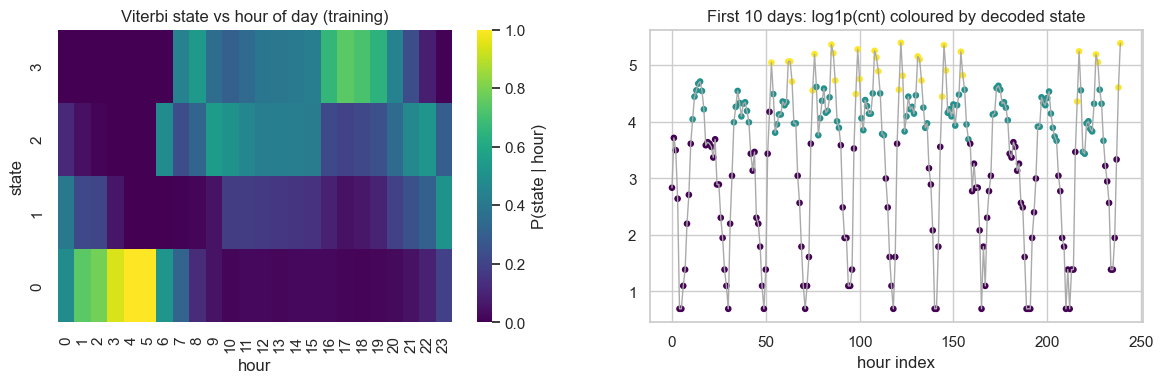

In [15]:
K_H = 4; hm = models[K_H]; o = np.argsort(hm.mu); 
hm.mu, hm.var, hm.pi, hm.A = hm.mu[o], hm.var[o], hm.pi[o], hm.A[np.ix_(o, o)]            # order states from low to high demand
path_tr, _ = hm.viterbi(z_tr)
names = {0: 'S0 (lowest)', 1: 'S1', 2: 'S2', 3: 'S3 (highest)'}
summ = pd.DataFrame({'state': [names[k] for k in range(K_H)], 'mean log1p(cnt)': hm.mu, 'std': np.sqrt(hm.var), 'typical cnt (expm1 mean)': np.expm1(hm.mu),
                     'share of training hours (Viterbi)': [(path_tr == k).mean() for k in range(K_H)], 'mean dwell time (h) = 1/(1-A_kk)': 1 / (1 - np.diag(hm.A)),
                     'P(working day)': [train.workingday.values[path_tr == k].mean() for k in range(K_H)], 'mean hour of day': [train.hr.values[path_tr == k].mean() for k in range(K_H)]})
display(summ); print('Transition matrix A (rows = from, cols = to):'); display(pd.DataFrame(hm.A, index=[f'from S{k}' for k in range(K_H)], columns=[f'to S{k}' for k in range(K_H)]))
R['hmm'] = {'K': K_H, 'mu': hm.mu.round(3).tolist(), 'std': np.sqrt(hm.var).round(3).tolist(), 'A': hm.A.round(3).tolist(), 'dwell': (1 / (1 - np.diag(hm.A))).round(2).tolist(), 'state_share': [float((path_tr == k).mean()) for k in range(K_H)]}
# state vs hour-of-day
hrst = pd.crosstab(train.hr.values, path_tr, normalize='index'); 
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8)); sns.heatmap(hrst.T, cmap='viridis', ax=ax[0], cbar_kws={'label': 'P(state | hour)'}); ax[0].set(title='Viterbi state vs hour of day (training)', xlabel='hour', ylabel='state'); ax[0].invert_yaxis()
sl = slice(0, 24 * 10); ax[1].plot(z_tr[sl], c='#aaa', lw=1); ax[1].scatter(range(24 * 10), z_tr[sl], c=path_tr[sl], cmap='viridis', s=14); ax[1].set(title='First 10 days: log1p(cnt) coloured by decoded state', xlabel='hour index')
savefig('u4_fig01_hmm_states')

Share of test hours per decoded state: [0.22986191 0.08342923 0.21518987 0.47151899]
Viterbi (single best path) vs posterior-mode (max γ) agree on 98.6% of test hours
Held-out log-likelihood per hour: train -1.043 | test -1.064


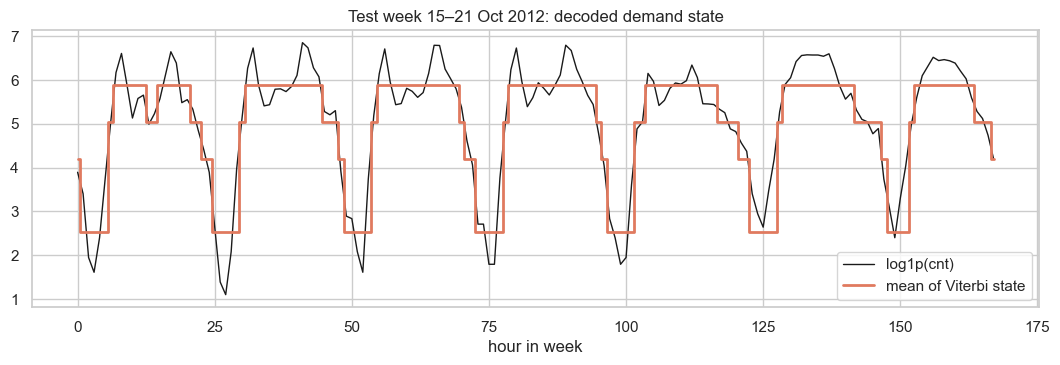

HMM one-step-ahead forecast: MAE 105.22 | RMSE 166.99 (count scale, test)


In [16]:
# ---- Viterbi decoding of the TEST period (parameters fixed from training; filter warmed up on the last 200 training hours)
ctx = 200; z_ctx = np.r_[z_tr[-ctx:], z_te]; path_te, _ = hm.viterbi(z_ctx); path_te = path_te[ctx:]
post_te = hm.posterior(z_ctx)[ctx:]
print('Share of test hours per decoded state:', np.bincount(path_te, minlength=K_H) / len(path_te))
print('Viterbi (single best path) vs posterior-mode (max γ) agree on %.1f%% of test hours' % (100 * (post_te.argmax(1) == path_te).mean()))
print('Held-out log-likelihood per hour: train %.3f | test %.3f' % (hm.loglik(z_tr) / len(z_tr), hm.loglik(z_ctx) / len(z_ctx)))
R['hmm'].update({'viterbi_vs_gamma_agree': float((post_te.argmax(1) == path_te).mean()), 'test_state_share': (np.bincount(path_te, minlength=K_H) / len(path_te)).tolist(), 'll_train': float(hm.loglik(z_tr) / len(z_tr)), 'll_test': float(hm.loglik(z_ctx) / len(z_ctx))})
wk = (test.date >= '2012-10-15') & (test.date <= '2012-10-21'); wi = np.where(wk.values)[0]
fig, ax = plt.subplots(figsize=(13, 3.6)); ax.plot(wi - wi[0], z_te[wi], c='k', lw=1, label='log1p(cnt)')
ax.step(wi - wi[0], hm.mu[path_te[wi]], c='#e07a5f', lw=2, where='mid', label='mean of Viterbi state'); ax.set(title='Test week 15–21 Oct 2012: decoded demand state', xlabel='hour in week'); ax.legend()
savefig('u4_fig02_hmm_test_week')
# prediction: one-step-ahead mean from the forward filter  E[z_{t+1}|z_{1:t}] = sum_k (alpha_t A)_k mu_k
al_ctx, _ = hm.forward(z_ctx); pred_state = al_ctx[:-1] @ hm.A @ hm.mu          # prediction of z_t from data up to t-1
hmm_pred_te = np.expm1(pred_state[ctx - 1:])                                       # aligned with test hours
print('HMM one-step-ahead forecast: MAE %.2f | RMSE %.2f (count scale, test)' % (mean_absolute_error(test.cnt, hmm_pred_te), np.sqrt(mean_squared_error(test.cnt, hmm_pred_te))))

## 11. Linear dynamical system and Kalman filter *(linear dynamical system / Kalman filter → Kalman forecasting of hourly count)*
LDS: $\;l_t=\phi\,l_{t-1}+w_t,\ w_t\sim\mathcal N(0,Q)$ (latent *demand-level anomaly*), $\;z_t=m_{hr,wd}+l_t+v_t,\ v_t\sim\mathcal N(0,R)$, where $m_{hr,wd}$ is the training mean of $\ln(1+cnt)$ for each hour-of-day × working-day cell (the strong daily rhythm). The Kalman filter alternates

* **predict:** $\hat l_{t|t-1}=\phi\hat l_{t-1|t-1},\quad P_{t|t-1}=\phi^2P_{t-1|t-1}+Q$
* **update:** $K_t=P_{t|t-1}/(P_{t|t-1}+R),\quad\hat l_{t|t}=\hat l_{t|t-1}+K_t(z_t-m-\hat l_{t|t-1}),\quad P_{t|t}=(1-K_t)P_{t|t-1}$

and its innovations give the exact log-likelihood, which is maximised over $(\phi,Q,R)$ on the **training** data only. The forecast for $h$ hours ahead is $m_{t+h}+\phi^h\hat l_{t|t}$ with variance $\phi^{2h}P_{t|t}+Q\sum_{i<h}\phi^{2i}+R$.

In [17]:
cell = lambda df: df.hr.values * 2 + df.workingday.values
prof_tab = pd.Series(z_tr).groupby(cell(train)).mean(); m_tr = prof_tab.reindex(range(48)).values
m_all = m_tr[cell(hour)]; r_all_ = z_all - m_all; r_tr, r_te = r_all_[:n_train], r_all_[n_train:]
print('Seasonal profile explains %.1f%% of training variance of log1p(cnt); residual s.d. %.3f' % (100 * (1 - r_tr.var() / z_tr.var()), r_tr.std()))
def kalman(y, phi, Q, Rv, l0=0., P0=None, return_all=False):
    T = len(y); P0 = Q / (1 - phi ** 2) if P0 is None and phi < 1 else (1.0 if P0 is None else P0)
    l, P = l0, P0; ll = 0.; lf = np.zeros(T); Pf = np.zeros(T); lp = np.zeros(T); Pp = np.zeros(T)
    for t in range(T):
        lpred, Ppred = phi * l, phi ** 2 * P + Q; S = Ppred + Rv; e = y[t] - lpred; Kt = Ppred / S
        ll += -.5 * (np.log(2 * np.pi * S) + e ** 2 / S); l = lpred + Kt * e; P = (1 - Kt) * Ppred
        lf[t], Pf[t], lp[t], Pp[t] = l, P, lpred, Ppred
    return (ll, lf, Pf, lp, Pp) if return_all else ll
nll = lambda th: -kalman(r_tr, 1 / (1 + np.exp(-th[0])), np.exp(th[1]), np.exp(th[2]), P0=1.0)
t0 = time.time(); opt = optimize.minimize(nll, [2., np.log(.05), np.log(.1)], method='L-BFGS-B'); phi_h, Q_h, R_h = 1 / (1 + np.exp(-opt.x[0])), np.exp(opt.x[1]), np.exp(opt.x[2])
print(f'MLE on training data ({time.time()-t0:.1f}s): φ = {phi_h:.4f}, Q = {Q_h:.5f}, R = {R_h:.5f} | train logL = {-opt.fun:.1f}')
print('Implied stationary s.d. of level anomaly = %.3f | AR half-life = %.1f h | signal-to-noise Q/R = %.3f' % (np.sqrt(Q_h / (1 - phi_h ** 2)), np.log(.5) / np.log(phi_h), Q_h / R_h))
# --- sanity check: the scalar Kalman filter equals the exact GLS/Gaussian likelihood computed from the full AR(1)+noise covariance on a short window
w = 60; idx = np.arange(w); Sig = Q_h / (1 - phi_h ** 2) * phi_h ** np.abs(idx[:, None] - idx[None]) + R_h * np.eye(w)
ll_direct = stats.multivariate_normal(np.zeros(w), Sig).logpdf(r_tr[:w]); ll_kf = kalman(r_tr[:w], phi_h, Q_h, R_h)
print('Kalman logL vs direct multivariate-normal logL on 60 h: %.8f vs %.8f' % (ll_kf, ll_direct), '→ match:', bool(np.isclose(ll_kf, ll_direct)))
R['kalman'] = {'phi': float(phi_h), 'Q': float(Q_h), 'R': float(R_h), 'half_life_h': float(np.log(.5) / np.log(phi_h)), 'profile_var_explained': float(1 - r_tr.var() / z_tr.var()), 'direct_check': bool(np.isclose(ll_kf, ll_direct))}

Seasonal profile explains 80.7% of training variance of log1p(cnt); residual s.d. 0.620


MLE on training data (0.6s): φ = 0.9349, Q = 0.04462, R = 0.02940 | train logL = -3101.9
Implied stationary s.d. of level anomaly = 0.595 | AR half-life = 10.3 h | signal-to-noise Q/R = 1.518
Kalman logL vs direct multivariate-normal logL on 60 h: -46.39877065 vs -46.39877065 → match: True


,Model,MAE,RMSE,R²,MAE (log scale)
0,"Kalman LDS, 1 h ahead",31.2005,51.0953,0.9463,0.1906
1,"Seasonal naive, same hour last week",78.1502,138.2014,0.6071,0.4631
2,"Seasonal naive, same hour yesterday",80.4603,134.7591,0.6264,0.4764
3,Persistence (cnt[t-1]),85.1821,129.6526,0.6542,0.4752
4,"Kalman LDS, 24 h ahead",102.7709,145.1490,0.5666,0.5038
5,"HMM (K=4), 1 h ahead",105.2174,166.9855,0.4264,0.5758
6,"Profile only (hour×workingday, no filter)",117.1769,164.7881,0.4414,0.5852


Empirical coverage of the nominal 95% Kalman prediction intervals (log scale): 1 h = 0.943 | 24 h = 0.977


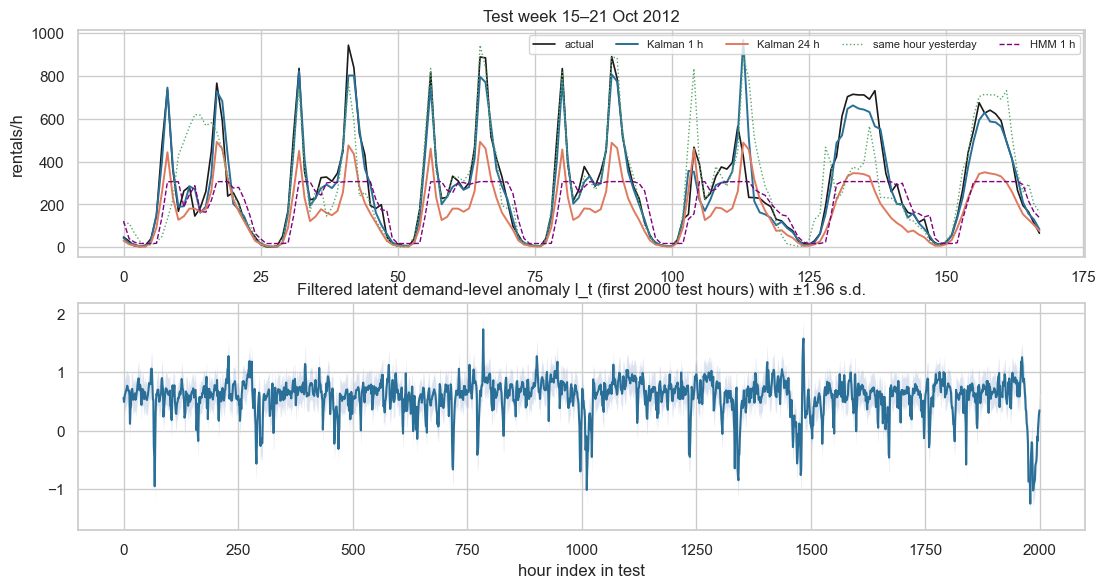

In [18]:
# ---- forecasting the test period.  The filter is run through train, then through test observing y_t only up to t-1 (true out-of-sample).
_, lf_all, Pf_all, lp_all, Pp_all = kalman(r_all_, phi_h, Q_h, R_h, P0=1.0, return_all=True)
def cnt_from(zhat): return np.expm1(zhat)
# 1-step ahead (made at t-1 for t):
z1 = m_all + lp_all; k1 = cnt_from(z1[n_train:])
# 24-step ahead (made at t-24 for t):
H = 24; l24 = phi_h ** H * lf_all; z24 = np.full(n, np.nan); z24[H:] = m_all[H:] + l24[:-H]; k24 = cnt_from(z24[n_train:])
sd1 = np.sqrt(Pp_all + R_h)[n_train:]; v24 = np.full(n, np.nan); v24[H:] = (phi_h ** (2 * H) * Pf_all[:-H] + Q_h * (1 - phi_h ** (2 * H)) / (1 - phi_h ** 2) + R_h); sd24 = np.sqrt(v24)[n_train:]
# baselines (all use only information available at forecast time)
y_te = test.cnt.values.astype(float); y_all = hour.cnt.values.astype(float)
def shift(arr, h): out = np.full(n, np.nan); out[h:] = arr[:-h]; return out
base = {'Persistence (cnt[t-1])': shift(y_all, 1)[n_train:], 'Seasonal naive, same hour yesterday': shift(y_all, 24)[n_train:], 'Seasonal naive, same hour last week': shift(y_all, 168)[n_train:], 'Profile only (hour×workingday, no filter)': cnt_from(m_all[n_train:])}
def score(name, pred): ok = ~np.isnan(pred); return {'Model': name, 'MAE': mean_absolute_error(y_te[ok], pred[ok]), 'RMSE': np.sqrt(mean_squared_error(y_te[ok], pred[ok])), 'R²': r2_score(y_te[ok], pred[ok]), 'MAE (log scale)': mean_absolute_error(np.log1p(y_te[ok]), np.log1p(np.maximum(pred[ok], 0)))}
fr = [score('Kalman LDS, 1 h ahead', k1), score('Kalman LDS, 24 h ahead', k24), score('HMM (K=4), 1 h ahead', hmm_pred_te)] + [score(k, v) for k, v in base.items()]
fdf_ = pd.DataFrame(fr).sort_values('MAE').reset_index(drop=True); display(fdf_)
R['forecast'] = fdf_.round(4).to_dict('records')
cov1 = np.mean(np.abs(np.log1p(y_te) - (z1[n_train:])) < 1.96 * sd1); cv24 = np.nanmean(np.abs(np.log1p(y_te) - z24[n_train:]) < 1.96 * sd24)
print('Empirical coverage of the nominal 95%% Kalman prediction intervals (log scale): 1 h = %.3f | 24 h = %.3f' % (cov1, cv24)); R['kalman'].update({'cov95_1h': float(cov1), 'cov95_24h': float(cv24)})
fig, ax = plt.subplots(2, 1, figsize=(13, 6.5)); wi = np.where(wk.values)[0]; x = np.arange(len(wi))
ax[0].plot(x, y_te[wi], 'k', lw=1.2, label='actual'); ax[0].plot(x, k1[wi], c='#2a6f97', lw=1.4, label='Kalman 1 h'); ax[0].plot(x, k24[wi], c='#e07a5f', lw=1.4, label='Kalman 24 h'); ax[0].plot(x, base['Seasonal naive, same hour yesterday'][wi], c='g', lw=1, ls=':', label='same hour yesterday'); ax[0].plot(x, hmm_pred_te[wi], c='purple', lw=1, ls='--', label='HMM 1 h'); ax[0].set(title='Test week 15–21 Oct 2012', ylabel='rentals/h'); ax[0].legend(ncol=5, fontsize=8)
ax[1].plot(np.arange(2000), lf_all[n_train:n_train + 2000], c='#2a6f97'); ax[1].fill_between(np.arange(2000), lf_all[n_train:n_train + 2000] - 1.96 * np.sqrt(Pf_all[n_train:n_train + 2000]), lf_all[n_train:n_train + 2000] + 1.96 * np.sqrt(Pf_all[n_train:n_train + 2000]), alpha=.2); ax[1].set(title='Filtered latent demand-level anomaly l_t (first 2000 test hours) with ±1.96 s.d.', xlabel='hour index in test')
savefig('u4_fig03_kalman_forecast')

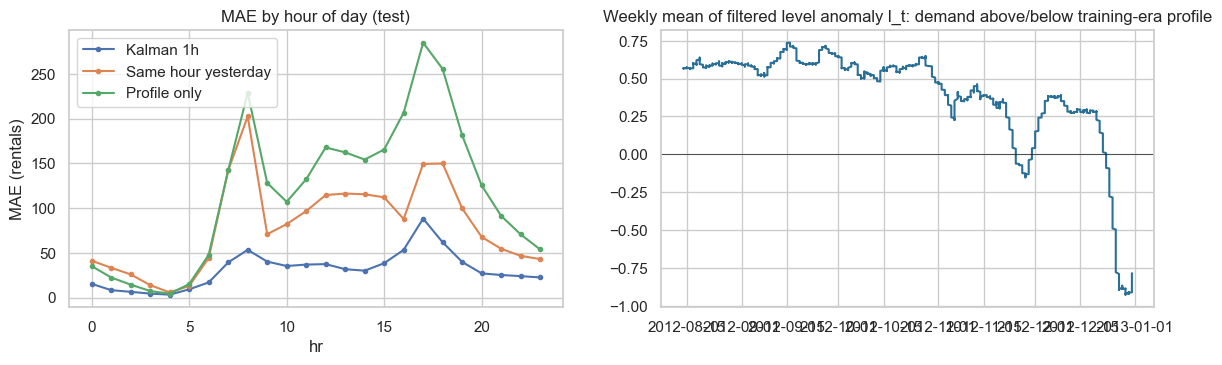

Mean filtered anomaly over test: 0.376 (positive ⇒ test period busier than the 2011–mid-2012 profile, consistent with the growth seen in Unit 1)


In [19]:
# error by hour of day for the best forecasts; and how the 2012 growth is tracked by the filter
err = pd.DataFrame({'hr': test.hr.values, 'Kalman 1h': np.abs(y_te - k1), 'Same hour yesterday': np.abs(y_te - base['Seasonal naive, same hour yesterday']), 'Profile only': np.abs(y_te - base['Profile only (hour×workingday, no filter)'])}).groupby('hr').mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6)); err.plot(ax=ax[0], marker='o', ms=3); ax[0].set(title='MAE by hour of day (test)', ylabel='MAE (rentals)')
ax[1].plot(test.date.values, pd.Series(lf_all[n_train:]).rolling(24 * 7).mean(), c='#2a6f97'); ax[1].axhline(0, c='k', lw=.5); ax[1].set(title='Weekly mean of filtered level anomaly l_t: demand above/below training-era profile')
savefig('u4_fig04_kalman_diag')
print('Mean filtered anomaly over test: %.3f (positive ⇒ test period busier than the 2011–mid-2012 profile, consistent with the growth seen in Unit 1)' % lf_all[n_train:].mean()); R['kalman']['mean_level_anomaly_test'] = float(lf_all[n_train:].mean())

## 12. Practice – HMM to predict sequential data
The HMM is used (a) to **decode** a hidden demand regime for every hour (Viterbi) and (b) to **predict** the next hour from the forward filter. The table in §11 compares both against the Kalman filter and naive baselines; interpretation is in §20.

In [20]:
# Practice: predict the demand *state* of the next hour with the HMM and check how often it is right.
al_ctx, _ = hm.forward(z_ctx); nxt = (al_ctx[:-1] @ hm.A).argmax(1)[ctx - 1:]        # most likely state for t, using data to t-1
print('HMM next-hour state prediction accuracy vs Viterbi-decoded state: %.3f' % (nxt == path_te).mean())
print('Naive baseline "state stays the same as the previous hour": %.3f' % (path_te[1:] == path_te[:-1]).mean())
R['hmm'].update({'next_state_acc': float((nxt == path_te).mean()), 'persist_state_acc': float((path_te[1:] == path_te[:-1]).mean())})

HMM next-hour state prediction accuracy vs Viterbi-decoded state: 0.725
Naive baseline "state stays the same as the previous hour": 0.777


# UNIT 5 – Trees, Boosting, Ensembles and GAM
## 13. Setup: demand-level classification
Target: `high_demand` = 1[cnt > 130] (training median), same as Unit 2. Features: the 12 raw columns of Unit 2 (trees need no scaling and handle hour/interaction structure themselves, which is why no hand-made `hr × workingday` dummies are needed). Chronological split as before; hyper-parameters are tuned by **TimeSeriesSplit inside the training period only**.

In [21]:
RAW_COLS = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
Xtr, Xte = train[RAW_COLS].astype(float).values, test[RAW_COLS].astype(float).values; ctr, cte = train.high_demand.values, test.high_demand.values
tscv = TimeSeriesSplit(n_splits=5); cls_rows, PROB, LAB, FIT = [], {}, {}, {}
def evaluate(name, model, fitted=True, note=''):
    if not fitted: t0 = time.time(); model.fit(Xtr, ctr); tt = time.time() - t0
    else: tt = np.nan
    p = model.predict_proba(Xte)[:, 1]; lab = (p >= .5).astype(int); PROB[name], LAB[name], FIT[name] = p, lab, model
    cls_rows.append({'Model': name, 'Accuracy': accuracy_score(cte, lab), 'Precision': precision_score(cte, lab), 'Recall': recall_score(cte, lab), 'F1': f1_score(cte, lab), 'ROC-AUC': roc_auc_score(cte, p), 'Log-loss': log_loss(cte, np.clip(p, 1e-6, 1 - 1e-6)), 'fit s': tt, 'note': note})
    return cls_rows[-1]
print('Features:', RAW_COLS, '| train/test:', Xtr.shape, Xte.shape, '| trivial baselines on test: always-high acc %.3f, always-low acc %.3f' % (cte.mean(), 1 - cte.mean()))

Features: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed'] | train/test: (13903, 12) (3476, 12) | trivial baselines on test: always-high acc 0.625, always-low acc 0.375


## 14. CART – classification tree *(Practice 1: CART for categorization)*
CART greedily splits on the feature/threshold that most reduces the **Gini impurity** $G=1-\sum_kp_k^2$ of the children (weighted by size). Fully grown trees overfit, so complexity is controlled by `max_depth`/`min_samples_leaf` or cost-complexity pruning $R_\alpha(T)=R(T)+\alpha|T|$; here the depth is chosen by time-series cross-validation.

,max_depth,CV accuracy (TimeSeriesSplit),train accuracy,test accuracy
0,1,0.7469,0.7728,0.8628
1,2,0.7086,0.8164,0.7529
2,3,0.7391,0.8281,0.7581
3,4,0.7444,0.8549,0.8564
4,5,0.8026,0.8813,0.8910
5,6,0.8289,0.8841,0.8970
6,7,0.8380,0.8925,0.9036
7,8,0.8359,0.9058,0.9010
8,9,0.8359,0.9201,0.9065
9,10,0.8307,0.9257,0.9019


Depth selected by CV (training data only): 11


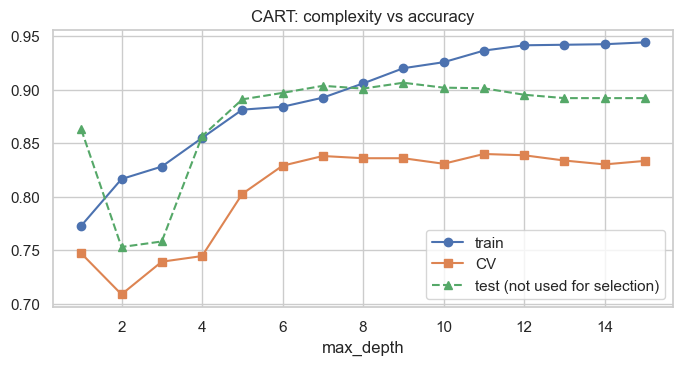

In [22]:
rows = []
for d in range(1, 16):
    accs = []
    for a, b in tscv.split(Xtr):
        m = DecisionTreeClassifier(max_depth=d, min_samples_leaf=10, random_state=SEED).fit(Xtr[a], ctr[a]); accs.append(accuracy_score(ctr[b], m.predict(Xtr[b])))
    m = DecisionTreeClassifier(max_depth=d, min_samples_leaf=10, random_state=SEED).fit(Xtr, ctr)
    rows.append({'max_depth': d, 'CV accuracy (TimeSeriesSplit)': np.mean(accs), 'train accuracy': m.score(Xtr, ctr), 'test accuracy': m.score(Xte, cte)})
cdf = pd.DataFrame(rows); display(cdf)
d_best = int(cdf.sort_values('CV accuracy (TimeSeriesSplit)', ascending=False).max_depth.iloc[0]); print('Depth selected by CV (training data only):', d_best)
fig, ax = plt.subplots(figsize=(8, 3.6)); ax.plot(cdf.max_depth, cdf['train accuracy'], 'o-', label='train'); ax.plot(cdf.max_depth, cdf['CV accuracy (TimeSeriesSplit)'], 's-', label='CV'); ax.plot(cdf.max_depth, cdf['test accuracy'], '^--', label='test (not used for selection)'); ax.set(title='CART: complexity vs accuracy', xlabel='max_depth'); ax.legend()
savefig('u5_fig01_cart_depth')
R['cart_depth_table'] = cdf.round(4).to_dict('records'); R['cart_depth'] = d_best

Pruned tree: α = 0.00151 → 26 leaves, depth 9 (unpruned min_leaf=10: 383 leaves)


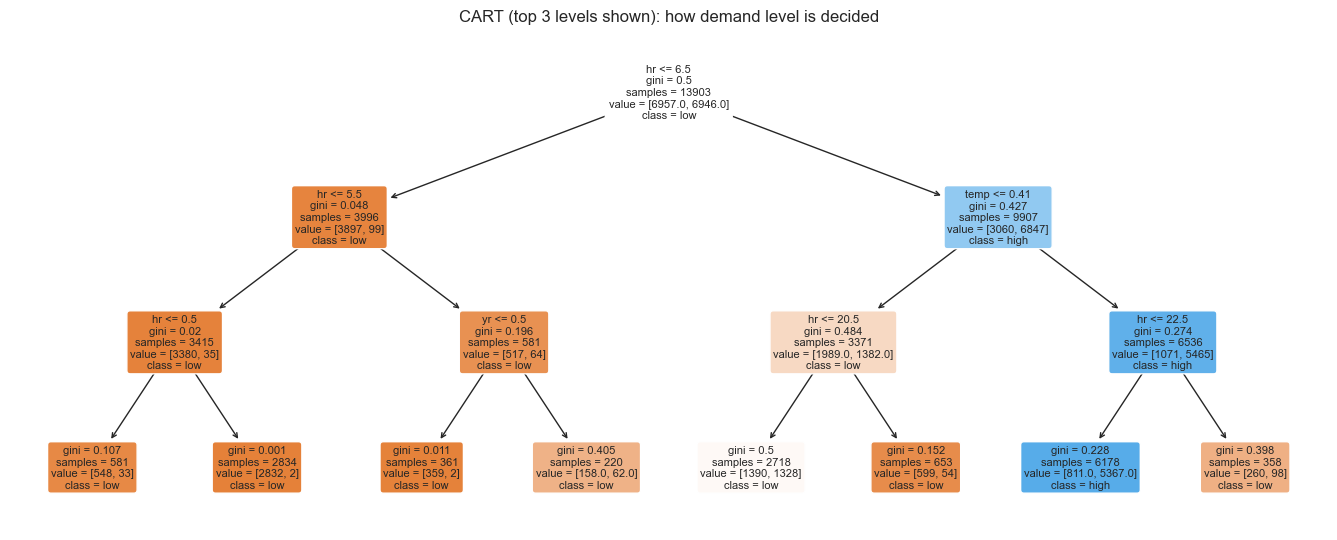

|--- hr <= 6.50
|   |--- hr <= 5.50
|   |   |--- hr <= 0.50
|   |   |   |--- class: 0
|   |   |--- hr >  0.50
|   |   |   |--- class: 0
|   |--- hr >  5.50
|   |   |--- yr <= 0.50
|   |   |   |--- class: 0
|   |   |--- yr >  0.50
|   |   |   |--- class: 0
|--- hr >  6.50
|   |--- temp <= 0.41
|   |   |--- hr <= 20.50
|   |   |   |--- class: 0
|   |   |--- hr >  20.50
|   |   |   |--- class: 0
|   |--- temp >  0.41
|   |   |--- hr <= 22.50
|   |   |   |--- class: 1
|   |   |--- hr >  22.50
|   |   |   |--- class: 0



,hr,atemp,workingday,yr,weathersit,hum,season,temp,mnth,weekday,windspeed,holiday
Gini importance,0.6066,0.1616,0.0472,0.0380,0.0324,0.0264,0.0257,0.0201,0.0172,0.0171,0.0075,0.0000


In [23]:
cart = DecisionTreeClassifier(max_depth=d_best, min_samples_leaf=10, random_state=SEED); evaluate('CART (CV depth)', cart, fitted=False, note=f'depth={d_best}')
# cost-complexity pruning alternative
path = DecisionTreeClassifier(min_samples_leaf=10, random_state=SEED).cost_complexity_pruning_path(Xtr, ctr); alphas = path.ccp_alphas[:-1][::max(1, len(path.ccp_alphas) // 25)]
cvs = [np.mean([accuracy_score(ctr[b], DecisionTreeClassifier(min_samples_leaf=10, ccp_alpha=a_, random_state=SEED).fit(Xtr[a], ctr[a]).predict(Xtr[b])) for a, b in tscv.split(Xtr)]) for a_ in alphas]
a_best = alphas[int(np.argmax(cvs))]; pr = DecisionTreeClassifier(min_samples_leaf=10, ccp_alpha=a_best, random_state=SEED); evaluate('CART (cost-complexity pruned)', pr, fitted=False); cls_rows[-1]['note'] = f'α={a_best:.5f}, leaves={pr.get_n_leaves()}'
print('Pruned tree: α = %.5f → %d leaves, depth %d (unpruned min_leaf=10: %d leaves)' % (a_best, pr.get_n_leaves(), pr.get_depth(), DecisionTreeClassifier(min_samples_leaf=10, random_state=SEED).fit(Xtr, ctr).get_n_leaves()))
fig, ax = plt.subplots(figsize=(17, 6.5)); plot_tree(DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=SEED).fit(Xtr, ctr), feature_names=RAW_COLS, class_names=['low', 'high'], filled=True, rounded=True, fontsize=8, ax=ax, impurity=True); ax.set_title('CART (top 3 levels shown): how demand level is decided')
savefig('u5_fig02_cart_tree')
print(export_text(DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=SEED).fit(Xtr, ctr), feature_names=RAW_COLS))
imp = pd.Series(cart.feature_importances_, index=RAW_COLS).sort_values(ascending=False); display(imp.to_frame('Gini importance').T)

## 15. Bagging and Random Forest *(ensemble learning: bagging / random forest)*
**Bagging** averages $B$ trees fitted to bootstrap resamples → variance falls by up to a factor $1/B$ when the trees are uncorrelated. **Random Forest** additionally considers only a random subset of $m_{try}$ features at each split to *decorrelate* the trees. The out-of-bag (OOB) samples (≈36.8% of the data per tree) give a free validation estimate. *Caveat:* OOB is a random-resampling estimate and is optimistic for time series; the chronological test score is the honest one.

In [24]:
bag = BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED), n_estimators=200, oob_score=True, n_jobs=-1, random_state=SEED); evaluate('Bagging (200 trees)', bag, fitted=False, note='')
cls_rows[-1]['note'] = f'OOB acc {bag.oob_score_:.3f}'
rf_try = {}
for mt in [2, 4, 'sqrt', 8, 12]:
    r_ = RandomForestClassifier(300, max_features=mt, min_samples_leaf=3, oob_score=True, n_jobs=-1, random_state=SEED).fit(Xtr, ctr); rf_try[str(mt)] = (r_.oob_score_, r_.score(Xte, cte))
print(pd.DataFrame(rf_try, index=['OOB accuracy (random)', 'test accuracy']).T.to_string())
rf = RandomForestClassifier(500, max_features='sqrt', min_samples_leaf=3, oob_score=True, n_jobs=-1, random_state=SEED); evaluate('Random Forest (500 trees)', rf, fitted=False); cls_rows[-1]['note'] = f'OOB acc {rf.oob_score_:.3f}'
print('Random forest OOB accuracy %.3f vs chronological test accuracy %.3f' % (rf.oob_score_, accuracy_score(cte, LAB['Random Forest (500 trees)'])))
R['rf_oob'] = float(rf.oob_score_); R['bag_oob'] = float(bag.oob_score_)
# variance reduction: single tree vs ensemble over bootstrap-stability (test accuracy of each tree)
tr_acc = [accuracy_score(cte, t.predict(Xte[:, f])) for t, f in zip(bag.estimators_[:50], bag.estimators_features_[:50])]
print('Individual bagged trees: test acc mean %.3f ± %.3f (min %.3f) → ensemble %.3f' % (np.mean(tr_acc), np.std(tr_acc), np.min(tr_acc), accuracy_score(cte, LAB['Bagging (200 trees)'])))
R['bag_tree_acc_mean'] = float(np.mean(tr_acc)); R['bag_tree_acc_sd'] = float(np.std(tr_acc))

      OOB accuracy (random)  test accuracy
2                    0.9167         0.9171
4                    0.9330         0.9226
sqrt                 0.9274         0.9197
8                    0.9440         0.9229
12                   0.9452         0.9186


Random forest OOB accuracy 0.928 vs chronological test accuracy 0.919
Individual bagged trees: test acc mean 0.887 ± 0.011 (min 0.856) → ensemble 0.919


## 16. Boosting: AdaBoost and Gradient Boosting *(boosting, adaptive basis-function models)*
Both fit the **adaptive basis-function model** $f(x)=\sum_{m=1}^M\beta_m\,\phi(x;\gamma_m)$ **stage-wise**, where each basis function $\phi$ is a small tree whose structure $\gamma_m$ is learned from data.
* **AdaBoost** (exponential loss): re-weights misclassified points by $w_n\leftarrow w_n e^{\alpha_m[y_n\ne h_m(x_n)]}$ with $\alpha_m=\tfrac12\ln\frac{1-\epsilon_m}{\epsilon_m}$ and outputs $\mathrm{sign}\sum_m\alpha_mh_m(x)$.
* **Gradient boosting** (logistic loss): each tree fits the negative gradient (pseudo-residuals) of the loss at the current ensemble, scaled by a learning rate $\nu$. Smaller $\nu$ + more trees = better generalisation but slower; the number of trees is chosen by CV.

,learning_rate,max_depth,best #trees,CV accuracy
0,0.0500,3,381,0.8975
1,0.2000,3,108,0.8962
2,0.1000,5,57,0.8948
3,0.1000,3,280,0.8943
4,0.0500,5,135,0.8931
5,0.2000,5,45,0.8922


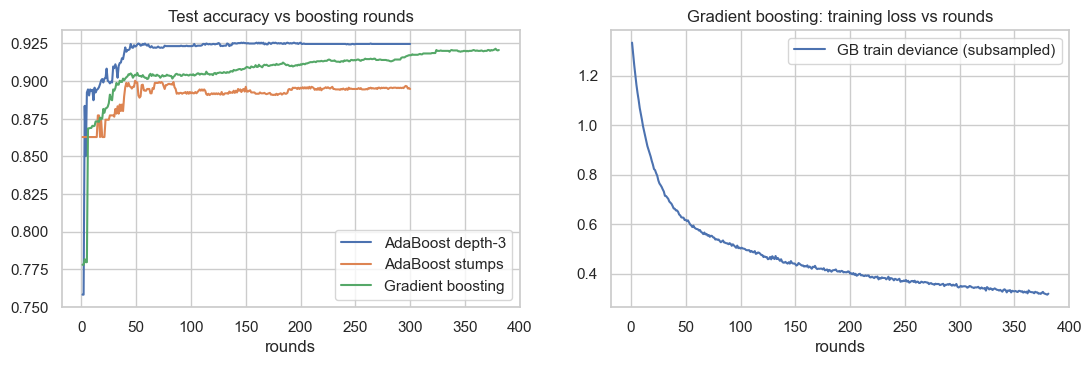

In [25]:
ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=3, random_state=SEED), n_estimators=300, learning_rate=.5, random_state=SEED); evaluate('AdaBoost (depth-3 trees, 300)', ada, fitted=False)
stump = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1, random_state=SEED), n_estimators=300, learning_rate=.5, random_state=SEED); evaluate('AdaBoost (stumps, 300)', stump, fitted=False)
# number of boosting rounds by time-series CV
grid = [(lr, md_) for lr in [.05, .1, .2] for md_ in [3, 5]]; res = []
for lr, md_ in grid:
    sc_ = []
    for a, b in tscv.split(Xtr):
        g_ = GradientBoostingClassifier(n_estimators=400, learning_rate=lr, max_depth=md_, subsample=.8, random_state=SEED).fit(Xtr[a], ctr[a])
        sc_.append([accuracy_score(ctr[b], p_) for p_ in g_.staged_predict(Xtr[b])])
    sc_ = np.mean(sc_, 0); res.append({'learning_rate': lr, 'max_depth': md_, 'best #trees': int(sc_.argmax()) + 1, 'CV accuracy': sc_.max()})
gdf5 = pd.DataFrame(res).sort_values('CV accuracy', ascending=False).reset_index(drop=True); display(gdf5); b0 = gdf5.iloc[0]
gb = GradientBoostingClassifier(n_estimators=int(b0['best #trees']), learning_rate=b0.learning_rate, max_depth=int(b0.max_depth), subsample=.8, random_state=SEED); evaluate('Gradient Boosting (CV-tuned)', gb, fitted=False, note=f"lr={b0.learning_rate}, depth={int(b0.max_depth)}, M={int(b0['best #trees'])}")
R['gb_grid'] = gdf5.round(4).to_dict('records')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(np.arange(1, 301), [accuracy_score(cte, p_) for p_ in ada.staged_predict(Xte)], label='AdaBoost depth-3'); ax[0].plot(np.arange(1, 301), [accuracy_score(cte, p_) for p_ in stump.staged_predict(Xte)], label='AdaBoost stumps')
ax[0].plot(np.arange(1, gb.n_estimators + 1), [accuracy_score(cte, p_) for p_ in gb.staged_predict(Xte)], label='Gradient boosting'); ax[0].set(title='Test accuracy vs boosting rounds', xlabel='rounds'); ax[0].legend()
ax[1].plot(np.arange(1, gb.n_estimators + 1), gb.train_score_, label='GB train deviance (subsampled)'); ax[1].set(title='Gradient boosting: training loss vs rounds', xlabel='rounds'); ax[1].legend()
savefig('u5_fig03_boosting')

## 17. Stacking and Bayesian model averaging *(ensemble learning: stacking; Bayesian model averaging)*
**Stacking** trains a meta-learner (logistic regression) on out-of-fold predictions of the base learners – with time-ordered folds here.

**Bayesian model averaging (BMA)** predicts $p(y|x,D)=\sum_m p(y|x,M_m,D)\,p(M_m|D)$ with posterior model weights $p(M_m|D)\propto p(D|M_m)\,p(M_m)$. The marginal likelihood is not available for these models; we use the standard practical approximation of a **held-out predictive likelihood**: weights $\propto\exp(\sum_{t\in V}\ln p(y_t|x_t,M_m))$ on the final 20% of the *training* period $V$ (models refitted on the earlier 80% of training), uniform prior. This is an approximation (stated as such) – note that BMA converges to the single best model, unlike stacking.

In [26]:
base = [('cart', DecisionTreeClassifier(max_depth=d_best, min_samples_leaf=10, random_state=SEED)), ('rf', RandomForestClassifier(200, min_samples_leaf=3, n_jobs=-1, random_state=SEED)),
        ('gb', GradientBoostingClassifier(n_estimators=int(b0['best #trees']), learning_rate=b0.learning_rate, max_depth=int(b0.max_depth), subsample=.8, random_state=SEED)), ('ada', AdaBoostClassifier(DecisionTreeClassifier(max_depth=3, random_state=SEED), n_estimators=150, learning_rate=.5, random_state=SEED))]
print('Stacking built manually: scikit-learn StackingClassifier needs a partition CV, which time-ordered folds are not; meta-features are expanding-window out-of-fold predictions.')
if True:
    oof = np.full((len(Xtr), len(base)), np.nan); folds = list(TimeSeriesSplit(n_splits=5).split(Xtr))
    for a, b in folds:
        for j, (_, mdl) in enumerate(base): oof[b, j] = clone(mdl).fit(Xtr[a], ctr[a]).predict_proba(Xtr[b])[:, 1]
    ok = ~np.isnan(oof).any(1); lg = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))
    meta = LogisticRegression(max_iter=1000).fit(lg(oof[ok]), ctr[ok]); fitted_base = [clone(m).fit(Xtr, ctr) for _, m in base]
    p = meta.predict_proba(lg(np.column_stack([m.predict_proba(Xte)[:, 1] for m in fitted_base])))[:, 1]; name = 'Stacking (CART+RF+GB+Ada → LR)'; lab = (p >= .5).astype(int); PROB[name], LAB[name] = p, lab
    cls_rows.append({'Model': name, 'Accuracy': accuracy_score(cte, lab), 'Precision': precision_score(cte, lab), 'Recall': recall_score(cte, lab), 'F1': f1_score(cte, lab), 'ROC-AUC': roc_auc_score(cte, p), 'Log-loss': log_loss(cte, np.clip(p, 1e-6, 1 - 1e-6)), 'fit s': np.nan, 'note': 'expanding-window OOF meta-features'})
    print('Meta-learner weights on logit(base predictions):', dict(zip([b_[0] for b_ in base], meta.coef_[0].round(3))))

Stacking built manually: scikit-learn StackingClassifier needs a partition CV, which time-ordered folds are not; meta-features are expanding-window out-of-fold predictions.


Meta-learner weights on logit(base predictions): {'cart': 0.052, 'rf': -0.036, 'gb': 0.428, 'ada': 1.803}


In [27]:
# ---- Bayesian model averaging by held-out predictive likelihood (validation = last 20% of the TRAINING period)
cut = int(.8 * len(Xtr)); Xa, Xv, ca, cv_ = Xtr[:cut], Xtr[cut:], ctr[:cut], ctr[cut:]
from sklearn.base import clone
cands = {n_: clone(m_) for n_, m_ in base}; cands['logreg'] = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
ll_val, pv_te = {}, {}
for n_, m_ in cands.items():
    m_.fit(Xa, ca); pv = np.clip(m_.predict_proba(Xv)[:, 1], 1e-4, 1 - 1e-4); ll_val[n_] = np.sum(cv_ * np.log(pv) + (1 - cv_) * np.log(1 - pv))
lw = np.array(list(ll_val.values())); w = np.exp(lw - lw.max()); w /= w.sum(); wts = dict(zip(ll_val, w))
print('Validation log-likelihood and BMA posterior weights:'); display(pd.DataFrame({'val logL': ll_val, 'weight p(M|D)': wts}))
refit = {n_: clone(m_).fit(Xtr, ctr) for n_, m_ in cands.items()}; p_bma = sum(wts[n_] * refit[n_].predict_proba(Xte)[:, 1] for n_ in refit); lab = (p_bma >= .5).astype(int)
PROB['Bayesian model averaging'], LAB['Bayesian model averaging'] = p_bma, lab
cls_rows.append({'Model': 'Bayesian model averaging', 'Accuracy': accuracy_score(cte, lab), 'Precision': precision_score(cte, lab), 'Recall': recall_score(cte, lab), 'F1': f1_score(cte, lab), 'ROC-AUC': roc_auc_score(cte, p_bma), 'Log-loss': log_loss(cte, np.clip(p_bma, 1e-6, 1 - 1e-6)), 'fit s': np.nan, 'note': 'held-out-likelihood weights'})
R['bma_weights'] = {k: float(v) for k, v in wts.items()}
# reference: unit 2 style logistic regression on the same raw features, to anchor the comparison
lr_raw = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)); _ = evaluate('Logistic regression (raw, reference)', lr_raw, fitted=False, note='Unit 2 baseline')

Validation log-likelihood and BMA posterior weights:


,val logL,weight p(M|D)
cart,"-1,166.5855",0.0000
rf,-604.4232,0.0000
gb,-546.6553,1.0000
ada,"-1,114.0529",0.0000
logreg,"-1,240.5811",0.0000


## 18. Classification comparison, confusion matrix and ROC

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Log-loss,fit s,note
0,Stacking (CART+RF+GB+Ada → LR),0.9266,0.9130,0.9756,0.9433,0.9779,0.1905,NaN,expanding-window OOF meta-features
1,Gradient Boosting (CV-tuned),0.9206,0.9385,0.9342,0.9364,0.9778,0.1832,2.3439,"lr=0.05, depth=3, M=381"
2,Bayesian model averaging,0.9206,0.9385,0.9342,0.9364,0.9778,0.1832,NaN,held-out-likelihood weights
3,Random Forest (500 trees),0.9186,0.9557,0.9121,0.9334,0.9775,0.2315,0.7994,OOB acc 0.928
4,"AdaBoost (depth-3 trees, 300)",0.9246,0.9330,0.9476,0.9402,0.9759,0.4245,2.2363,
5,Bagging (200 trees),0.9194,0.9380,0.9328,0.9354,0.9756,0.2229,2.9030,OOB acc 0.943
6,"AdaBoost (stumps, 300)",0.8947,0.8887,0.9508,0.9187,0.9641,0.5329,0.8929,
7,CART (cost-complexity pruned),0.8984,0.9171,0.9209,0.9190,0.9425,0.3298,0.0210,"α=0.00151, leaves=26"
8,CART (CV depth),0.9091,0.9329,0.9209,0.9269,0.9414,0.4948,0.0201,depth=11
9,"Logistic regression (raw, reference)",0.8239,0.8287,0.9057,0.8655,0.8864,0.4212,0.0064,Unit 2 baseline


Best by ROC-AUC: Stacking (CART+RF+GB+Ada → LR) | best by accuracy: Stacking (CART+RF+GB+Ada → LR)


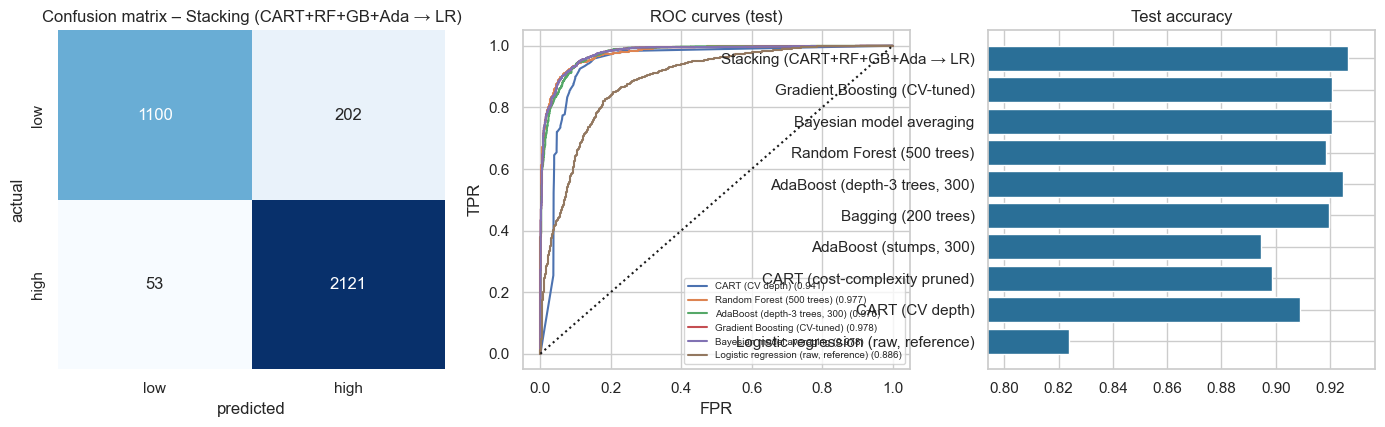

Stacking (CART+RF+GB+Ada → LR): TN=1100 FP=202 FN=53 TP=2121 → specificity 0.845, recall 0.976


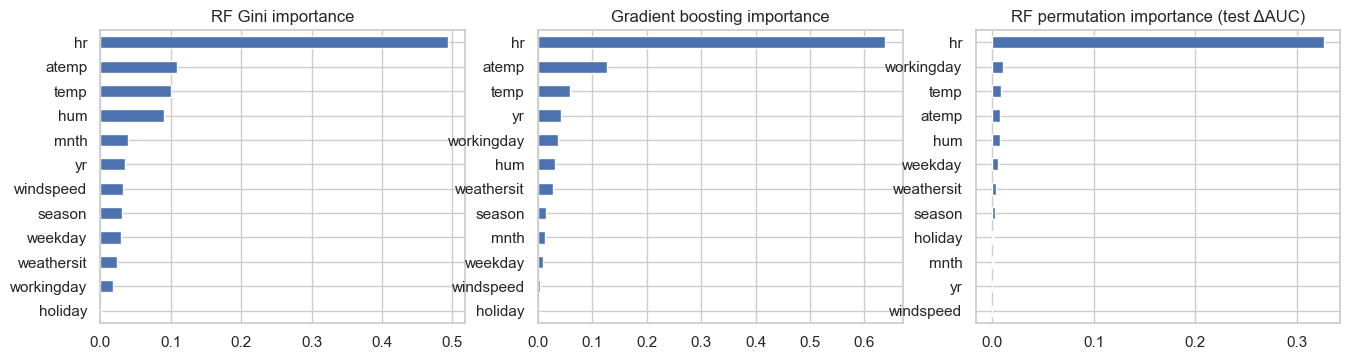

Top-3 by permutation importance: ['hr', 'workingday', 'temp']


In [28]:
cls = pd.DataFrame(cls_rows).sort_values('ROC-AUC', ascending=False).reset_index(drop=True); display(cls); R['cls'] = cls.round(4).fillna('').to_dict('records')
top = cls.Model.iloc[0]; print('Best by ROC-AUC:', top, '| best by accuracy:', cls.sort_values('Accuracy', ascending=False).Model.iloc[0])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
cm = confusion_matrix(cte, LAB[top]); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0], xticklabels=['low', 'high'], yticklabels=['low', 'high']); ax[0].set(title=f'Confusion matrix – {top}', xlabel='predicted', ylabel='actual')
for nme in ['CART (CV depth)', 'Random Forest (500 trees)', 'AdaBoost (depth-3 trees, 300)', 'Gradient Boosting (CV-tuned)', 'Bayesian model averaging', 'Logistic regression (raw, reference)']:
    f_, t_, _ = roc_curve(cte, PROB[nme]); ax[1].plot(f_, t_, label=f'{nme} ({roc_auc_score(cte, PROB[nme]):.3f})')
ax[1].plot([0, 1], [0, 1], 'k:'); ax[1].set(title='ROC curves (test)', xlabel='FPR', ylabel='TPR'); ax[1].legend(fontsize=7)
ax[2].barh(cls.Model[::-1], cls.Accuracy[::-1], color='#2a6f97'); ax[2].set(xlim=(cls.Accuracy.min() - .03, cls.Accuracy.max() + .01), title='Test accuracy')
savefig('u5_fig04_classification')
tn, fp, fn, tp = cm.ravel(); print(f'{top}: TN={tn} FP={fp} FN={fn} TP={tp} → specificity {tn/(tn+fp):.3f}, recall {tp/(tp+fn):.3f}')
rf_imp = pd.Series(FIT['Random Forest (500 trees)'].feature_importances_, index=RAW_COLS).sort_values(); gb_imp = pd.Series(FIT['Gradient Boosting (CV-tuned)'].feature_importances_, index=RAW_COLS).sort_values()
from sklearn.inspection import permutation_importance
pi_ = permutation_importance(FIT['Random Forest (500 trees)'], Xte, cte, n_repeats=8, random_state=SEED, scoring='roc_auc', n_jobs=-1); pim = pd.Series(pi_.importances_mean, index=RAW_COLS).sort_values()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8)); rf_imp.plot.barh(ax=ax[0], title='RF Gini importance'); gb_imp.plot.barh(ax=ax[1], title='Gradient boosting importance'); pim.plot.barh(ax=ax[2], title='RF permutation importance (test ΔAUC)')
savefig('u5_fig05_importance'); R['importance'] = {'rf_gini_top': rf_imp.sort_values(ascending=False).head(4).round(3).to_dict(), 'perm_top': pim.sort_values(ascending=False).head(4).round(3).to_dict()}
print('Top-3 by permutation importance:', list(pim.sort_values(ascending=False).index[:3]))

## 19. Generalised additive model *(GAM for count vs temperature & hour)*
$g(\mathbb E[cnt])=\beta_0+f_1(\text{temp})+f_2(\text{hr})+f_3(\text{hum})+\dots+\text{categorical terms}$ – a sum of smooth one-dimensional functions: more flexible than linear regression, but (unlike trees) each effect stays **interpretable**. Smooth terms are **cubic B-splines**; counts are modelled with a **Poisson** distribution and log link ($\mathbb E[cnt]=\exp(\eta)$, so effects are *multiplicative*), fitted by IRLS with a small ridge penalty (smoothness control). An interaction `hour × workingday` is included because Unit 1 showed the two commuting-vs-leisure shapes.

In [29]:
def gam_design(spl_cols, knots=8):
    smooth = [(f'spl_{c}', SplineTransformer(n_knots=knots, degree=3, include_bias=False, extrapolation='constant'), [c]) for c in spl_cols]
    return smooth
cat_cols = ['season', 'weathersit', 'weekday', 'mnth']
def build_gam(alpha, hr_wd=True):
    parts = gam_design(['temp', 'hum', 'windspeed']) + [('hr_wd0', SplineTransformer(n_knots=12, degree=3, include_bias=False, extrapolation='periodic' if False else 'constant'), ['hr_nw']), ('hr_wd1', SplineTransformer(n_knots=12, degree=3, include_bias=False, extrapolation='constant'), ['hr_w'])] + [('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols + ['yr', 'holiday', 'workingday'])]
    return make_pipeline(ColumnTransformer(parts), PoissonRegressor(alpha=alpha, max_iter=1000))
def gdat(df): d = df[['temp', 'hum', 'windspeed', 'season', 'weathersit', 'weekday', 'mnth', 'yr', 'holiday', 'workingday']].copy(); d['hr_w'] = np.where(df.workingday == 1, df.hr, -1); d['hr_nw'] = np.where(df.workingday == 0, df.hr, -1); return d
Gtr, Gte = gdat(train), gdat(test)
# hour spline is evaluated only on the matching workingday group; the other group is a constant (-1 → 0 contribution after the spline is zeroed by the mask)
rows = []
for a_ in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]:
    sc_ = []
    for a, b in tscv.split(Gtr):
        m = build_gam(a_).fit(Gtr.iloc[a], train.cnt.values[a]); sc_.append(mean_absolute_error(train.cnt.values[b], m.predict(Gtr.iloc[b])))
    rows.append({'penalty α': a_, 'CV MAE': np.mean(sc_)})
gam_cv = pd.DataFrame(rows); display(gam_cv); a_g = gam_cv.sort_values('CV MAE').iloc[0]['penalty α']
gam = build_gam(a_g).fit(Gtr, train.cnt.values); pg = gam.predict(Gte)
lin = Ridge(1.0).fit(StandardScaler().fit(train[RAW_COLS]).transform(train[RAW_COLS]), train.cnt.values); sc_lin = StandardScaler().fit(train[RAW_COLS]); pl = Ridge(1.0).fit(sc_lin.transform(train[RAW_COLS]), train.cnt.values).predict(sc_lin.transform(test[RAW_COLS]))
rfr_p = None
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
rfr = RandomForestRegressor(300, min_samples_leaf=3, n_jobs=-1, random_state=SEED).fit(Xtr, train.cnt.values); gbr = GradientBoostingRegressor(n_estimators=400, learning_rate=.05, max_depth=5, subsample=.8, random_state=SEED).fit(Xtr, train.cnt.values)
g_rows = [{'Model': n_, 'RMSE': np.sqrt(mean_squared_error(y_te, p_)), 'MAE': mean_absolute_error(y_te, p_), 'R²': r2_score(y_te, p_)} for n_, p_ in [('Poisson GAM (splines)', pg), ('Linear ridge, raw features (reference)', pl), ('Random-forest regressor', rfr.predict(Xte)), ('Gradient-boosting regressor', gbr.predict(Xte))]]
gcmp = pd.DataFrame(g_rows).sort_values('MAE'); display(gcmp); R['gam'] = {'alpha': float(a_g), 'table': gcmp.round(4).to_dict('records'), 'cv': gam_cv.round(4).to_dict('records')}

,penalty α,CV MAE
0,0.0000,69.6669
1,0.0001,69.6053
2,0.0010,69.3056
3,0.0100,68.5557
4,0.1000,65.0588
5,1.0000,69.9913


,Model,RMSE,MAE,R²
0,Poisson GAM (splines),68.4390,44.8879,0.9037
3,Gradient-boosting regressor,69.0419,45.5200,0.9019
2,Random-forest regressor,70.7424,45.6106,0.8971
1,"Linear ridge, raw features (reference)",183.2793,138.2918,0.3090


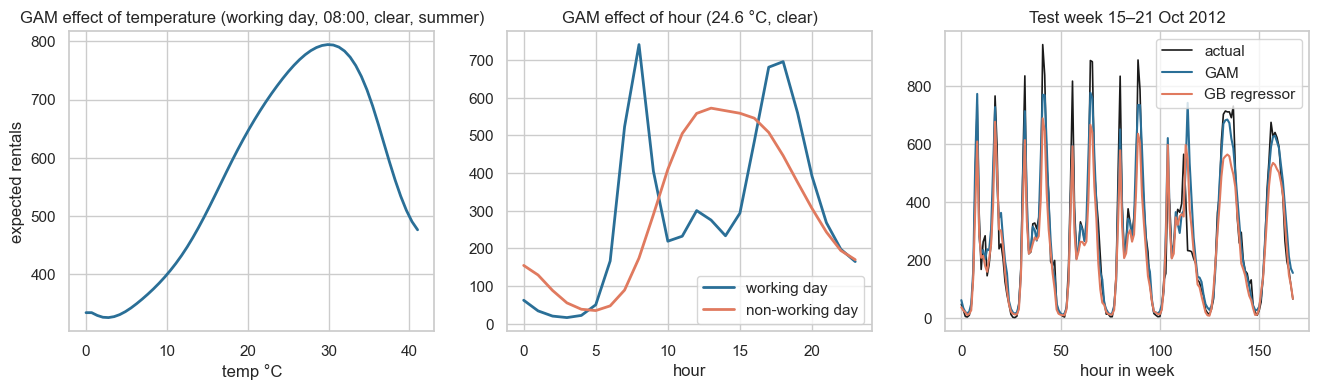

GAM temperature effect peaks at 29.9 °C; at 5 °C predicted demand is 42% of the peak value


In [30]:
# partial-dependence ("smooth term") plots of the GAM: vary one input, hold others at typical values
base_row = Gtr.median(numeric_only=True).to_frame().T.iloc[0]; fig, ax = plt.subplots(1, 3, figsize=(16, 3.9))
tg = np.linspace(0, 1, 60); D = pd.DataFrame([base_row] * 60); D['temp'] = tg; D['hr_w'] = 8; D['hr_nw'] = -1; D['workingday'] = 1; D['season'] = 3; D['weathersit'] = 1; D['weekday'] = 2; D['mnth'] = 7; D['yr'] = 1; D['holiday'] = 0
ax[0].plot(tg * 41, gam.predict(D), c='#2a6f97', lw=2); ax[0].set(title='GAM effect of temperature (working day, 08:00, clear, summer)', xlabel='temp °C', ylabel='expected rentals')
hh = np.arange(24)
for wd, c, l in [(1, '#2a6f97', 'working day'), (0, '#e07a5f', 'non-working day')]:
    D2 = pd.DataFrame([base_row] * 24); D2['hr_w'] = hh if wd else -1; D2['hr_nw'] = -1 if wd else hh; D2['workingday'] = wd; D2['temp'] = .6; D2['season'] = 3; D2['weathersit'] = 1; D2['weekday'] = 2 if wd else 6; D2['mnth'] = 7; D2['yr'] = 1; D2['holiday'] = 0
    ax[1].plot(hh, gam.predict(D2), c=c, lw=2, label=l)
ax[1].set(title='GAM effect of hour (24.6 °C, clear)', xlabel='hour'); ax[1].legend()
wi = np.where(wk.values)[0]; ax[2].plot(np.arange(len(wi)), y_te[wi], 'k', lw=1.2, label='actual'); ax[2].plot(np.arange(len(wi)), pg[wi], c='#2a6f97', label='GAM'); ax[2].plot(np.arange(len(wi)), gbr.predict(Xte)[wi], c='#e07a5f', label='GB regressor'); ax[2].set(title='Test week 15–21 Oct 2012', xlabel='hour in week'); ax[2].legend()
savefig('u5_fig06_gam')
tt = gam.predict(D); print('GAM temperature effect peaks at %.1f °C; at 5 °C predicted demand is %.0f%% of the peak value' % (tg[tt.argmax()] * 41, 100 * tt[np.argmin(np.abs(tg * 41 - 5))] / tt.max()))
R['gam']['temp_peak_C'] = float(tg[tt.argmax()] * 41)

## 20. Cross-unit summary, interpretation, limitations, conclusion

In [31]:
best_cls = cls.iloc[0]; rf_acc = cls.set_index('Model').loc['Random Forest (500 trees)']; lr_ref = cls.set_index('Model').loc['Logistic regression (raw, reference)']; cart_row = cls.set_index('Model').loc['CART (CV depth)']
fb = fdf_.set_index('Model')
print(f'''UNIT 3 – Clustering / PCA
 • Silhouette and Davies–Bouldin both select K={R["kmeans"]["K"]} profile shapes (finer K=3 is much weaker: silhouette {ev.iloc[3]["Silhouette"]:.3f}). K-means silhouette {R["kmeans"]["sil"]:.3f}, DB {R["kmeans"]["DB"]:.3f}; cluster sizes {R["kmeans"]["sizes"]}, peak hours {R["kmeans"]["peak_hours"]}. ARI with the working-day label = {R["kmeans"]["ARI_workingday"]:.3f}: the clusters recover the commute-vs-leisure split almost exactly; the {R["kmeans_mismatch"]["n"]} disagreements ({R["kmeans_mismatch"]["holidays"]} of them official holidays) are days whose shape differs from their calendar flag.
 • GMM (EM in PCA space): BIC alone prefers a finer K={R["gmm"]["K_BIC"]} (full-covariance components reward splitting the two main shapes into finer sub-groups; the extra groups are not separated well, cf. the weak K=3 silhouette); at K={R["kmeans"]["K"]}, {R["gmm"]["uncertain_days"]} day(s) have max responsibility < 0.9 (the soft-assignment benefit is small because the two shapes are well separated). ARI(GMM, K-means) = {R["gmm"]["ARI_vs_kmeans"]:.3f}; ARI(Ward, K-means) = {R["hier"]["ARI_vs_kmeans"]:.3f}; 3 near-empty days (incl. Hurricane Sandy, 29 Oct 2012: 22 rentals) were excluded as noise.
 • PCA: {R["pca"]["M90"]} components retain 90% of weather–time variance (Kaiser keeps {R["pca"]["Kaiser"]}); a linear model on those PCs gets test R² {R["pca"]["r2_pc"]:.3f} for log1p(cnt) vs {R["pca"]["r2_all"]:.3f} with all raw features, so little predictive information is lost. FA picks q = {R["fa"]["q_best"]}.
UNIT 4 – HMM / Kalman
 • HMM with K={R["hmm"]["K"]} states (log-mean {R["hmm"]["mu"]}) – mean dwell times {R["hmm"]["dwell"]} h; Baum–Welch log-likelihood non-decreasing: {R["hmm_em_monotone"]}; forward and Viterbi match brute force: {R["hmm_checks"]["forward_matches_bruteforce"]}/{R["hmm_checks"]["viterbi_matches_bruteforce"]}.
 • Kalman LDS (φ={R["kalman"]["phi"]:.3f}, half-life {R["kalman"]["half_life_h"]:.1f} h): 1-h-ahead MAE {fb.loc["Kalman LDS, 1 h ahead","MAE"]:.1f} vs persistence {fb.loc["Persistence (cnt[t-1])","MAE"]:.1f}, same-hour-yesterday {fb.loc["Seasonal naive, same hour yesterday","MAE"]:.1f}, profile-only {fb.loc["Profile only (hour×workingday, no filter)","MAE"]:.1f}; the HMM's 1-h MAE is {fb.loc["HMM (K=4), 1 h ahead","MAE"]:.1f} – worse than persistence, because its 4 states are coarse level buckets (std ≈ 0.3–0.9 on log scale) with no hour-of-day input; its value is decoding/interpretation, not forecasting. Next-hour state prediction accuracy {R["hmm"]["next_state_acc"]:.3f} vs {R["hmm"]["persist_state_acc"]:.3f} for "state unchanged".
 • 95% intervals: empirical coverage {R["kalman"]["cov95_1h"]:.3f} (1 h) and {R["kalman"]["cov95_24h"]:.3f} (24 h).
UNIT 5 – Ensembles / GAM
 • Best classifier by AUC: {best_cls.Model} (acc {best_cls.Accuracy:.3f}, AUC {best_cls["ROC-AUC"]:.3f}); single CART: acc {cart_row.Accuracy:.3f}, AUC {cart_row["ROC-AUC"]:.3f}; Random Forest: acc {rf_acc.Accuracy:.3f}, AUC {rf_acc["ROC-AUC"]:.3f}; Unit-2 logistic reference: acc {lr_ref.Accuracy:.3f}, AUC {lr_ref["ROC-AUC"]:.3f}.
 • Most important inputs (RF permutation): {list(R["importance"]["perm_top"])} – consistent with Unit 1 (hour-of-day × working day dominates, then temperature).
 • Poisson GAM temperature effect peaks at {R["gam"]["temp_peak_C"]:.1f} °C; GAM test MAE {gcmp.set_index("Model").loc["Poisson GAM (splines)","MAE"]:.1f} vs GB regressor {gcmp.set_index("Model").loc["Gradient-boosting regressor","MAE"]:.1f}.''')

UNIT 3 – Clustering / PCA
 • Silhouette and Davies–Bouldin both select K=2 profile shapes (finer K=3 is much weaker: silhouette 0.239). K-means silhouette 0.504, DB 0.840; cluster sizes [236, 492], peak hours [13, 17]. ARI with the working-day label = 0.939: the clusters recover the commute-vs-leisure split almost exactly; the 11 disagreements (3 of them official holidays) are days whose shape differs from their calendar flag.
 • GMM (EM in PCA space): BIC alone prefers a finer K=4 (full-covariance components reward splitting the two main shapes into finer sub-groups; the extra groups are not separated well, cf. the weak K=3 silhouette); at K=2, 1 day(s) have max responsibility < 0.9 (the soft-assignment benefit is small because the two shapes are well separated). ARI(GMM, K-means) = 0.972; ARI(Ward, K-means) = 0.945; 3 near-empty days (incl. Hurricane Sandy, 29 Oct 2012: 22 rentals) were excluded as noise.
 • PCA: 8 components retain 90% of weather–time variance (Kaiser keeps 4); a li

In [32]:
print('''LIMITATIONS
 • Clustering: 731 days only; K=2 is the best-supported number of shapes (BIC prefers more, finer groups); cluster labels are descriptive, not causal. Missing clock-hours were set to 0 rentals in the day profiles.
 • HMM: one-dimensional Gaussian emissions on log-counts with the 165 missing hours skipped; because the daily cycle dominates, decoded states largely track time of day (see the state-vs-hour heat-map) rather than purely "regimes". Adding hour as an input-output HMM would separate them – left for future work.
 • Kalman: a scalar linear-Gaussian model on log scale; expm1(mean) estimates the median not the mean of the count; the stationary φ<1 cannot represent the 2011→2012 structural growth beyond what the filter tracks adaptively.
 • Trees/ensembles: chronological test period is busier than training (62.5% vs 50% high-demand), so tree models cannot extrapolate beyond the training range (piecewise-constant) – a general limit of tree ensembles under trend. OOB scores are optimistic for time series.
 • BMA uses a held-out predictive likelihood as proxy for the marginal likelihood.''')

LIMITATIONS
 • Clustering: 731 days only; K=2 is the best-supported number of shapes (BIC prefers more, finer groups); cluster labels are descriptive, not causal. Missing clock-hours were set to 0 rentals in the day profiles.
 • HMM: one-dimensional Gaussian emissions on log-counts with the 165 missing hours skipped; because the daily cycle dominates, decoded states largely track time of day (see the state-vs-hour heat-map) rather than purely "regimes". Adding hour as an input-output HMM would separate them – left for future work.
 • Kalman: a scalar linear-Gaussian model on log scale; expm1(mean) estimates the median not the mean of the count; the stationary φ<1 cannot represent the 2011→2012 structural growth beyond what the filter tracks adaptively.
 • Trees/ensembles: chronological test period is busier than training (62.5% vs 50% high-demand), so tree models cannot extrapolate beyond the training range (piecewise-constant) – a general limit of tree ensembles under trend. OOB score

In [33]:
print('''CONCLUSION (Units 3–5)
 • Unit 3 shows that daily demand has two clearly separated recurring shapes (working-day commuter shape with 8 h and 17 h peaks vs non-working leisure shape with a midday hump) and that weather–time features are well summarised by few latent dimensions.
 • Unit 4 shows that demand has strong sequential structure: a Kalman level model on top of an hour×workday profile gives sharp short-horizon forecasts with close-to-nominal 95% intervals, while the HMM provides interpretable hidden demand states and decoding.
 • Unit 5 shows that nonlinear ensembles outperform single trees and the linear Unit-2 classifier, and that a GAM gives an interpretable smooth temperature/hour effect at nearly the accuracy of boosting.
Together with PBL I (Units 1–2) the project covers the full syllabus on one dataset with one consistent chronological protocol.''')
def js(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.ndarray,)): return o.tolist()
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
json.dump(R, open('results_units345.json', 'w'), indent=1, default=js); print('saved results_units345.json with', len(R), 'top-level entries')

CONCLUSION (Units 3–5)
 • Unit 3 shows that daily demand has two clearly separated recurring shapes (working-day commuter shape with 8 h and 17 h peaks vs non-working leisure shape with a midday hump) and that weather–time features are well summarised by few latent dimensions.
 • Unit 4 shows that demand has strong sequential structure: a Kalman level model on top of an hour×workday profile gives sharp short-horizon forecasts with close-to-nominal 95% intervals, while the HMM provides interpretable hidden demand states and decoding.
 • Unit 5 shows that nonlinear ensembles outperform single trees and the linear Unit-2 classifier, and that a GAM gives an interpretable smooth temperature/hour effect at nearly the accuracy of boosting.
Together with PBL I (Units 1–2) the project covers the full syllabus on one dataset with one consistent chronological protocol.
saved results_units345.json with 27 top-level entries
